# Jovian Aurora Multi-Instrument Pipeline V2
End-to-end pipeline for processing XMM-Newton gap-binned segments and aligning them with Juno WAVES & MAG in-situ Das2 spectrograms.

In [37]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LogNorm
from matplotlib.ticker import MultipleLocator, AutoMinorLocator, FixedLocator
from matplotlib.gridspec import GridSpec
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.patheffects as pe
import scipy.signal as signal
from scipy.signal import find_peaks
from scipy.fft import rfft, rfftfreq
from astropy.io import fits
from astropy.time import Time
from astropy.table import Table
from astropy.coordinates import get_body_barycentric, solar_system_ephemeris
from astropy.constants import c
import astropy.units as u
from astropy.timeseries import LombScargle
from das2 import get_source
import das2
import warnings

warnings.filterwarnings('ignore')
plt.rcParams.update({'font.size': 12, 'axes.grid': True, 'figure.autolayout': True})

In [38]:
# --- Configuration ---
XMM_OBS_ID = 'P0801931901'

# Replace these with your local file paths or data directory structures
XMM_EVENT_FILE_PN = f"Data_Files/Fenn_Data/EPIC_{XMM_OBS_ID}_PN_North_RFT.fit"
XMM_EVENT_FILE_M1 = f"Data_Files/Fenn_Data/EPIC_{XMM_OBS_ID}_M1_North_RFT.fit"
XMM_EVENT_FILE_M2 = f"Data_Files/Fenn_Data/EPIC_{XMM_OBS_ID}_M2_North_RFT.fit"
xmm_files = [XMM_EVENT_FILE_PN, XMM_EVENT_FILE_M1, XMM_EVENT_FILE_M2]

# Temporal binning and filtering (in seconds)
BIN_SIZE = 10.0
MIN_PERIOD_SEC = 60.0    # 1 minute
MAX_PERIOD_SEC = 900.0   # 15 minutes

# Das2 API URIs
SERVER_URL_WAVES = "tag:das2.org,2012:site:/uiowa/juno/wav/survey/das2"
SERVER_URL_EFC   = "tag:das2.org,2012:site:/uiowa/juno/fgm/electroncyclotron/das2"
SERVER_URL_EPH   = "tag:das2.org,2012:site:/uiowa/juno/ephemeris/jovicentric/das2"

WAVES_FIG_OUTDIR = "WAVES_FIGS"
os.makedirs(WAVES_FIG_OUTDIR, exist_ok=True)

In [39]:
# --- Standard Signal Processing Functions ---
def compute_and_check_ls_xmm(time_array, data_array, ax, title="Lomb-Scargle Periodogram"):
    """
    Computes the Lomb-Scargle periodogram for the 1-15 min band, plots it with FAP levels,
    and returns True if any peak exceeds the 5% False Alarm Probability (p <= 0.05).
    """
    # Time in seconds relative to start
    t_sec = time_array - time_array[0]
    
    # Detrend data
    detrended = signal.detrend(data_array)
    
    # Frequency bounds for 1 to 15 minutes
    fmin = 1.0 / MAX_PERIOD_SEC
    fmax = 1.0 / MIN_PERIOD_SEC
    
    # Compute Lomb-Scargle
    ls = LombScargle(t_sec, detrended, normalization='standard')
    freq, power = ls.autopower(minimum_frequency=fmin, maximum_frequency=fmax, samples_per_peak=5)
    periods_min = (1.0 / freq) / 60.0
    
    # Calculate False Alarm Probabilities
    try:
        fap_05 = ls.false_alarm_level(0.05, method='baluev', minimum_frequency=fmin, maximum_frequency=fmax)
        fap_01 = ls.false_alarm_level(0.01, method='baluev', minimum_frequency=fmin, maximum_frequency=fmax)
    except Exception:
        fap_05 = ls.false_alarm_level(0.05, method='naive', minimum_frequency=fmin, maximum_frequency=fmax)
        fap_01 = ls.false_alarm_level(0.01, method='naive', minimum_frequency=fmin, maximum_frequency=fmax)
        
    # Plotting
    ax.plot(periods_min, power, color='k')
    ax.axhline(fap_05, color='orange', linestyle='--', label='5% FAP (p=0.05)')
    ax.axhline(fap_01, color='red', linestyle=':', label='1% FAP (p=0.01)')
    
    ax.set_xlim(MAX_PERIOD_SEC/60.0, MIN_PERIOD_SEC/60.0)
    ax.set_xlabel('Period (Minutes)')
    ax.set_ylabel('LS Power')
    ax.set_title(title)
    ax.axvspan(1, 15, color='red', alpha=0.1, label='1-15 min QPP Band')
    ax.legend(loc='upper right', fontsize='small')
    
    # Evaluate significance: Check if any power within the targeted band exceeds the p=0.05 threshold
    is_significant = np.any(power > fap_05)
    
    return is_significant

def compute_and_plot_cwt(time_array, data_array, dt, ax, title="Continuous Wavelet Transform (Morlet)"):
    """Computes and plots the CWT to show temporal evolution of periodicities."""
    detrended = signal.detrend(data_array)
    
    frequencies = np.linspace(1/MAX_PERIOD_SEC, 1/MIN_PERIOD_SEC, 100)
    w0 = 6.0
    widths = w0 * 2 * np.pi / (2 * np.pi * frequencies * dt)
    
    cwtm = signal.cwt(detrended, signal.morlet2, widths, w=w0)
    power = np.abs(cwtm)**2
    
    t_hours = (time_array - time_array[0]) / 3600.0
    periods_min = (1.0 / frequencies) / 60.0
    
    T, P = np.meshgrid(t_hours, periods_min)
    
    c = ax.contourf(T, P, power, 100, cmap='viridis', extend='both')
    ax.set_ylabel('Period (Minutes)')
    ax.set_xlabel('Time from Start (Hours)')
    ax.set_title(title)
    ax.set_ylim(15, 1)
    plt.colorbar(c, ax=ax, label='Power')

In [40]:
# --- XMM-Newton Gap Detection & Binning Pipeline ---
def find_gaps(times_cxcsec: np.ndarray, threshold: float = 3600.0):
    dt = np.diff(times_cxcsec)
    indices = np.where(dt > threshold)[0]
    gaps = [(times_cxcsec[i], times_cxcsec[i + 1]) for i in indices]
    return gaps, indices

def categorize_segment(counts: np.ndarray, low_thresh: float = 300, high_thresh: float = 1000):
    total = float(np.sum(counts))
    if total < low_thresh: return 'low'
    elif total < high_thresh: return 'medium'
    return 'high'

def dynamic_bin_size(category: str, base_bin: int = 10):
    if category == 'low': return base_bin * 4
    elif category == 'medium': return base_bin * 2
    return base_bin

def prepare_segment_bins(raw_segment: np.ndarray, base_bin: int):
    bins0 = np.arange(float(np.nanmin(raw_segment)), float(np.nanmax(raw_segment)) + base_bin, base_bin)
    counts0, _ = np.histogram(raw_segment, bins=bins0)
    category = categorize_segment(counts0)

    seg_bin = dynamic_bin_size(category, base_bin)
    bins = np.arange(float(np.nanmin(raw_segment)), float(np.nanmax(raw_segment)) + seg_bin, seg_bin)
    hist_counts, edges = np.histogram(raw_segment, bins=bins)
    hist_centers = edges[:-1] + 0.5 * seg_bin
    
    return seg_bin, hist_centers, hist_counts, category

def load_all_segments_xmm(event_files, gap_threshold_s=3600.0, base_bin=10):
    list_cxc = []
    for file in event_files:
        try:
            data = Table.read(file, format="fits")
            t = Time(data['TIME'], format='cxcsec', scale='tt')
            
            with solar_system_ephemeris.set('de432s'):
                jup = get_body_barycentric('jupiter', t)
                xmm = get_body_barycentric('earth', t) 
                
            distance_au = (jup - xmm).norm()
            light_time_s = (distance_au.to('m') / c).to('s').value
            
            corrected_t = t - light_time_s * u.s
            list_cxc.append(corrected_t.cxcsec)
        except FileNotFoundError:
            print(f"Warning: {file} not found. Skipping.")
            continue
            
    if not list_cxc:
        print("No XMM files loaded. Generating mock data for testing layout.")
        t_mock = np.arange(0, 7200, 30)
        counts_mock = 100 + 20*np.sin(2*np.pi*t_mock/240) + np.random.normal(0,5, len(t_mock))
        return [{'segment_id': 1, 't_binned': t_mock, 'counts_binned': counts_mock, 'bin_size': 30, 'category': 'high'}]
        
    combined_times = np.concatenate(list_cxc)
    t_sorted = combined_times[np.argsort(combined_times)]
    
    _, gap_idx = find_gaps(t_sorted, threshold=gap_threshold_s)
    split_pts = np.concatenate(([0], gap_idx + 1, [len(t_sorted)]))
    
    segment_data = []
    seg_id = 1 
    for i in range(len(split_pts) - 1):
        seg = t_sorted[split_pts[i]: split_pts[i + 1]]
        if seg.size > 5:
            seg_bin, t_binned, counts_binned, category = prepare_segment_bins(seg, base_bin)
            segment_data.append({
                'segment_id': seg_id,
                't_binned': t_binned,
                'counts_binned': counts_binned,
                'bin_size': seg_bin,
                'category': category
            })
            seg_id += 1
            
    return segment_data

In [41]:
# --- WAVES Das2 Fetch & Plotting Routine ---
def add_inset_cbar(ax, im, label, *, height="55%", width="2.5%", pad=0.02):
    cax = inset_axes(ax, width=width, height=height, loc="center right",
                     bbox_to_anchor=(0, 0, 1, 1), bbox_transform=ax.transAxes, borderpad=0.6)
    cb = ax.figure.colorbar(im, cax=cax)
    cb.set_label(label)
    cb.ax.tick_params(labelsize=8)
    return cb

def shrink_cax(cax, frac=0.60):
    pos = cax.get_position()
    new_h = pos.height * frac
    new_y = pos.y0 + (pos.height - new_h) / 2
    cax.set_position([pos.x0, new_y, pos.width, new_h])

def make_waves_segment(start_time, end_time, label="segment", 
                       server_url=SERVER_URL_WAVES, whis_min=300.0, whis_max=3000.0,
                       period_min=1.0, period_max=15.0, peak_detect_min=2.5, num_peaks=4, ls_nfreq=5000,
                       plot_fce=True, plot_b_panel=True):
    
    source = get_source(server_url)
    ds = source.get({'time': (start_time, end_time)})
    if len(ds) < 2:
        print(f"Expected at least two datasets from DAS2 for {label}. Skipping.")
        return
    
    whis = ds[0]
    middle = ds[1]

    def extract_arrays(d):
        f_arr = d['frequency']['center'].array
        freqs = f_arr[0, :] if getattr(f_arr, "ndim", 1) > 1 else f_arr
        t_arr = d['Time']['center'].array
        times = t_arr[:, 0] if getattr(t_arr, "ndim", 1) > 1 else t_arr
        spec = d['spec_dens']['center'].array.squeeze()
        if spec.ndim != 2: raise ValueError("spec_dens not 2D")
        if spec.shape[1] != freqs.size: spec = spec.T
        return (np.array(times, dtype='datetime64[ms]'), np.asarray(freqs, float), np.asarray(spec, float))

    times, freqs, spec = extract_arrays(whis)
    times_mid, freqs_mid, spec_mid = extract_arrays(middle)

    spec_plot = spec.copy()
    spec_plot[~np.isfinite(spec_plot)] = np.nan
    spec_plot[spec_plot <= 0] = np.nan

    spec_mid_plot = spec_mid.copy()
    spec_mid_plot[~np.isfinite(spec_mid_plot)] = np.nan
    spec_mid_plot[spec_mid_plot <= 0] = np.nan

    times_b = freqs_b = spec_b = spec_b_plot = None
    if plot_b_panel:
        try:
            ds_b = source.get({'time': (start_time, end_time, 1.0), 'b': True})
            if len(ds_b) > 0:
                times_b, freqs_b, spec_b = extract_arrays(ds_b[0])
                spec_b_plot = spec_b.copy()
                spec_b_plot[~np.isfinite(spec_b_plot)] = np.nan
                spec_b_plot[spec_b_plot <= 0] = np.nan
            else:
                plot_b_panel = False
        except Exception as e:
            print(f"Failed to retrieve magnetic dataset: {e}")
            plot_b_panel = False

    mask_band = (freqs >= whis_min) & (freqs <= whis_max)
    sum_sd = np.nansum(spec_plot[:, mask_band], axis=1)

    t0 = times[0]
    t_sec = (times - t0) / np.timedelta64(1, 's')
    dtcad = float(np.nanmedian(np.diff(t_sec)))
    
    coeff = np.polyfit(t_sec, sum_sd, 1)
    trend = np.polyval(coeff, t_sec)
    resid0 = sum_sd - trend - np.nanmean(sum_sd - trend)

    fmin, fmax = 1.0 / (period_max * 60.0), 1.0 / (period_min * 60.0)
    freq = np.linspace(fmin, fmax, ls_nfreq)
    ls = LombScargle(t_sec, resid0, normalization="standard", center_data=False)
    power = ls.power(freq)
    periods_ls = (1.0 / freq) / 60.0
    
    order = np.argsort(periods_ls)
    periods_ls, power_ls = periods_ls[order], power[order]
    mask_p = (periods_ls >= period_min) & (periods_ls <= period_max)
    periods_m, pow_m = periods_ls[mask_p], power_ls[mask_p]

    peaks, _ = find_peaks(pow_m)
    peak_periods = periods_m[peaks[np.argsort(pow_m[peaks])][-num_peaks:]] if peaks.size > 0 else np.array([])
    peak_periods = peak_periods[peak_periods >= peak_detect_min]

    try:
        thr_10 = ls.false_alarm_level(0.10, method="baluev", minimum_frequency=fmin, maximum_frequency=fmax)
        thr_01 = ls.false_alarm_level(0.01, method="baluev", minimum_frequency=fmin, maximum_frequency=fmax)
    except:
        thr_10 = ls.false_alarm_level(0.10, method="naive", minimum_frequency=fmin, maximum_frequency=fmax)
        thr_01 = ls.false_alarm_level(0.01, method="naive", minimum_frequency=fmin, maximum_frequency=fmax)

    fig = plt.figure(figsize=(12, 14), dpi=150)
    outer_gs = GridSpec(2, 1, figure=fig, height_ratios=[6, 1], hspace=0.35)
    inner_gs = outer_gs[0].subgridspec(4, 2, height_ratios=[1, 1, 1, 0.45], width_ratios=[1, 0.03], wspace=0.02, hspace=0.00)

    ax_spec_mid = fig.add_subplot(inner_gs[0, 0])
    ax_spec     = fig.add_subplot(inner_gs[1, 0], sharex=ax_spec_mid)
    ax_bspec    = fig.add_subplot(inner_gs[2, 0], sharex=ax_spec_mid)
    ax_ts       = fig.add_subplot(inner_gs[3, 0], sharex=ax_spec_mid)
    ax_fft      = fig.add_subplot(outer_gs[1])

    cax_mid = fig.add_subplot(inner_gs[0, 1])
    cax_wh  = fig.add_subplot(inner_gs[1, 1])
    cax_b   = fig.add_subplot(inner_gs[2, 1])
    cax_ts  = fig.add_subplot(inner_gs[3, 1])
    cax_ts.axis("off")

    im_waves_mid = ax_spec_mid.pcolormesh(times_mid, freqs_mid, spec_mid_plot.T, norm=LogNorm(vmin=1e-14, vmax=1e-11), cmap="turbo", shading="nearest")
    ax_spec_mid.set_ylim(2e4, 2e5)
    ax_spec_mid.set_yscale("log")
    ax_spec_mid.set_facecolor("black")
    ax_spec_mid.set_ylabel("Frequency (Hz)")
    ax_spec_mid.set_title(f"Juno Waves Spectrogram | {label}")
    cb_mid = fig.colorbar(im_waves_mid, cax=cax_mid)
    cb_mid.set_label('ESD')
    shrink_cax(cax_mid, frac=0.90)

    im_waves_wh = ax_spec.pcolormesh(times, freqs, spec_plot.T, norm=LogNorm(vmin=1e-14, vmax=1e-8), cmap="turbo", shading="nearest")
    ax_spec.set_ylim(5e1, 2e4)
    ax_spec.set_yscale("log")
    ax_spec.set_facecolor("black")
    ax_spec.set_ylabel("Frequency (Hz)")
    cb_wh = fig.colorbar(im_waves_wh, cax=cax_wh)
    cb_wh.set_label('ESD')
    shrink_cax(cax_wh, frac=0.90)

    ax_spec.plot(times, np.full(times.shape, whis_min), "--w", lw=2, alpha=0.9)
    ax_spec.plot(times, np.full(times.shape, whis_max), "--w", lw=2, alpha=0.9)

    if plot_b_panel and spec_b_plot is not None:
        im_b = ax_bspec.pcolormesh(times_b, freqs_b, spec_b_plot.T, norm=LogNorm(vmin=1e-9, vmax=1e-4), cmap="turbo", shading="nearest")
        ax_bspec.set_ylim(5e1, 2e4)
        ax_bspec.set_yscale("log")
        ax_bspec.set_facecolor("black")
        ax_bspec.set_ylabel("Frequency (Hz)")
        cb_b = fig.colorbar(im_b, cax=cax_b)
        cb_b.set_label('PSD')
        shrink_cax(cax_b, frac=0.9)
    else:
        ax_bspec.axis("off")
        cax_b.axis("off")

    for ax in [ax_spec_mid, ax_spec, ax_bspec]:
        ax.tick_params(axis="x", labelbottom=False)

    axes_for_overlays = [ax_spec_mid, ax_spec]
    if plot_b_panel and ax_bspec.axison:
        axes_for_overlays.append(ax_bspec)

    if plot_fce:
        try:
            efc_source = das2.get_source(SERVER_URL_EFC)
            ds_efc = efc_source.get({"time": (start_time, end_time)})[0]
            efc_freq = np.asarray(ds_efc["fce"]["center"].array, float)
            efc_time = np.array(ds_efc["time"]["center"].array, dtype="datetime64[ms]")
            mask_fce = np.isfinite(efc_freq) & (efc_freq > 0)
            for ax_ov in axes_for_overlays:
                ax_ov.plot(efc_time[mask_fce], efc_freq[mask_fce], color="red", linewidth=1.0, alpha=0.9, label="f_ce (FGM)" if ax_ov is ax_spec else None)
        except Exception as e:
            print(f"Failed to load FGM f_ce: {e}")

    ax_spec.legend(loc="upper right", frameon=True, ncols=2, fontsize="small")

    ax_ts.plot(times, sum_sd, linewidth=0.5, color="green")
    ax_ts.set_ylabel("Summed ESD")
    ax_ts.set_xlim(times[0], times[-1])
    ax_ts.set_yscale("log")

    major, minor = mdates.HourLocator(interval=1), mdates.MinuteLocator(interval=10)
    ax_ts.xaxis.set_major_locator(major)
    ax_ts.xaxis.set_minor_locator(minor)
    ax_ts.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))

    try:
        eph_src = get_source(SERVER_URL_EPH)
        ds_eph  = eph_src.get({"time": (start_time, end_time, int(max(1, round(dtcad))))})[0]
        rad   = ds_eph["radius"]["center"].array
        lon3  = ds_eph["long"]["center"].array
        mlatE = ds_eph["mlat"]["center"].array
        mltE  = ds_eph["mlt"]["center"].array
        if getattr(mltE, "dtype", None) is not None and mltE.dtype.kind == "m":
            mltE = (mltE / np.timedelta64(1, "h")).astype(float)

        t0h = times[0].astype("datetime64[h]")
        t1h = times[-1].astype("datetime64[h]") + np.timedelta64(1, "h")
        maj = np.arange(t0h, t1h, np.timedelta64(1, "h"))
        all_ticks = np.unique(np.concatenate(([times[0]], maj, [times[-1]])))
        all_tick_nums = mdates.date2num([t.tolist() for t in all_ticks])
        
        ax_ts.xaxis.set_major_locator(FixedLocator(all_tick_nums))
        idx_eph = [np.argmin(np.abs(times - mt)) for mt in all_ticks]
        
        for j, (lab, arr) in enumerate(zip(["R_J", "Lon_III", "MLat", "MLT"], [rad, lon3, mlatE, mltE])):
            sax = ax_ts.secondary_xaxis(-0.15 * (j + 2), functions=(lambda x: x, lambda x: x))
            sax.xaxis.set_major_locator(FixedLocator(all_tick_nums))
            sax.set_xticklabels([f"{v:.1f}" for v in arr[idx_eph]], rotation=0, va="top", fontsize=8)
            sax.spines["bottom"].set_visible(False)
            sax.tick_params(axis="x", length=0)
            txt = sax.set_xlabel(lab, fontsize=8, labelpad=-8.5, loc="left")
            txt.set_x(-0.03)
            txt.set_ha("right")
    except Exception as e:
        print(f"Failed to load Ephemeris: {e}")

    ax_fft.plot(periods_m, pow_m, label="LS power")
    ax_fft.axhline(thr_10, ls="--", lw=1, color="k", alpha=0.8)
    ax_fft.axhline(thr_01, ls="--", lw=1, color="k", alpha=0.8)
    for p in peak_periods:
        ax_fft.axvline(p, ls="--", color="red")
        ax_fft.text(p, -0.05, f"{p:.2f}", transform=ax_fft.get_xaxis_transform(), rotation=90, va="top", ha="center", color="red", fontsize=7)
    ax_fft.set_xlim(period_max, period_min)
    ax_fft.set_xlabel("Period (minutes)")
    ax_fft.set_ylabel("Power")
    ax_fft.legend(loc="upper left", frameon=False, ncols=2, fontsize="small")

    plt.tight_layout(rect=[0, 0.02, 1, 0.96])
    plt.show()


--- Processing XMM Segment 1 ---
Start Time (UTC) : 2019-04-01 23:23:05.583
End Time (UTC)   : 2019-04-02 04:20:05.583
Duration         : 4.95 hours
Dynamic Bin Size : 20.0s


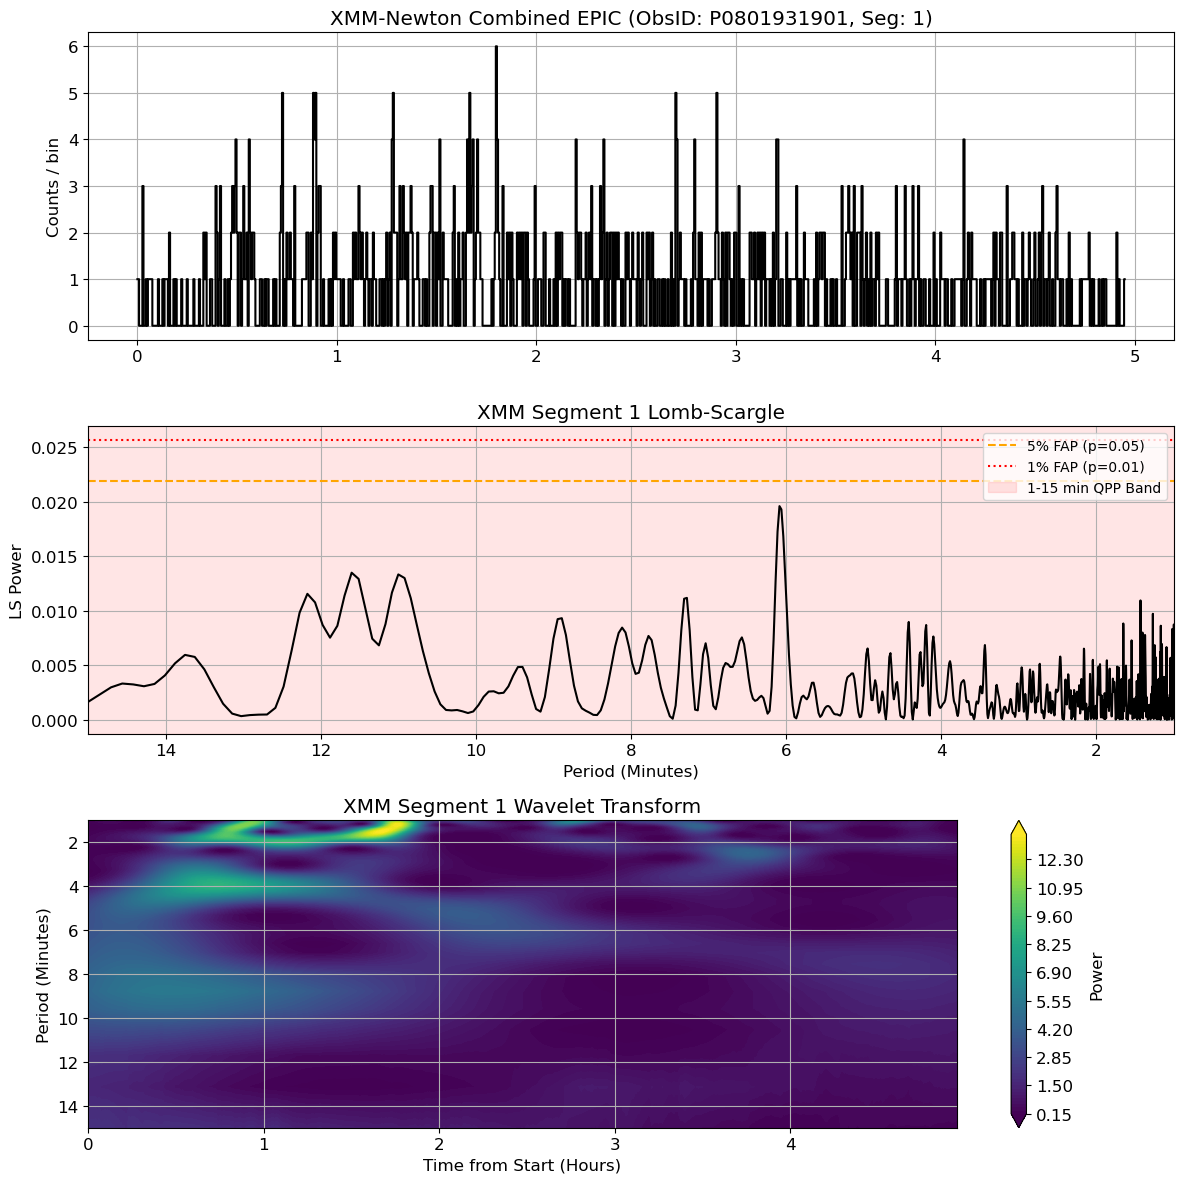

✖ [SKIP] No statistically significant periodicities (p <= 0.05) detected in XMM Segment 1.

--- Processing XMM Segment 2 ---
Start Time (UTC) : 2019-04-02 07:56:06.219
End Time (UTC)   : 2019-04-02 14:15:16.219
Duration         : 6.32 hours
Dynamic Bin Size : 10.0s


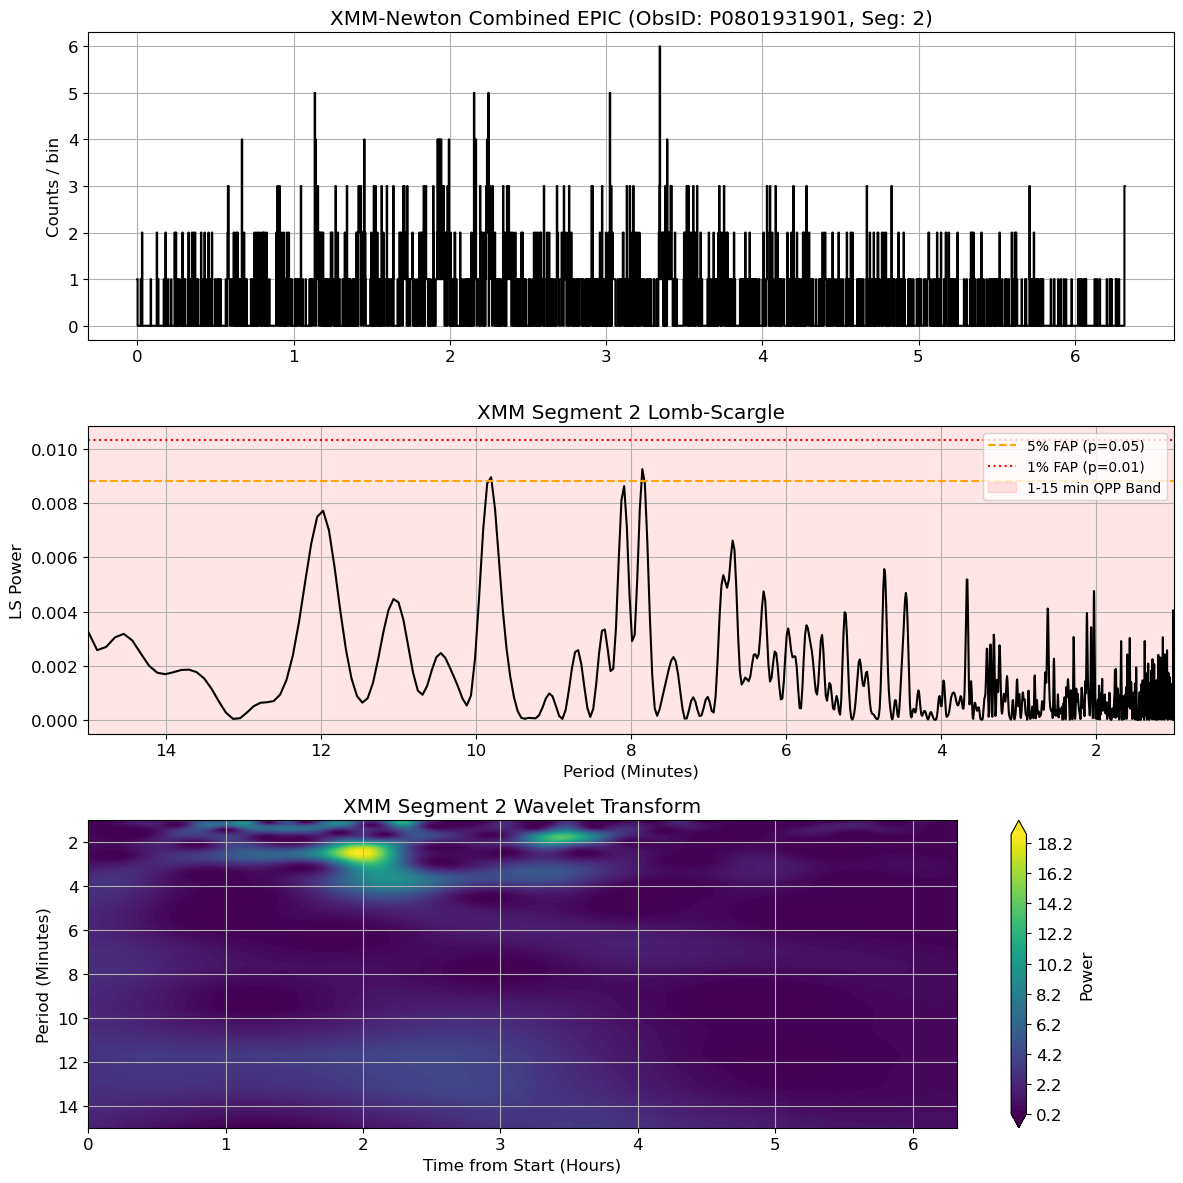

✔ [MATCH] Significant periodicities detected in XMM Segment 2! Proceeding to Das2 WAVES fetch...
Querying Das2 Time Range: 2019-04-02T07:56:06.219Z to 2019-04-02T14:15:16.219Z


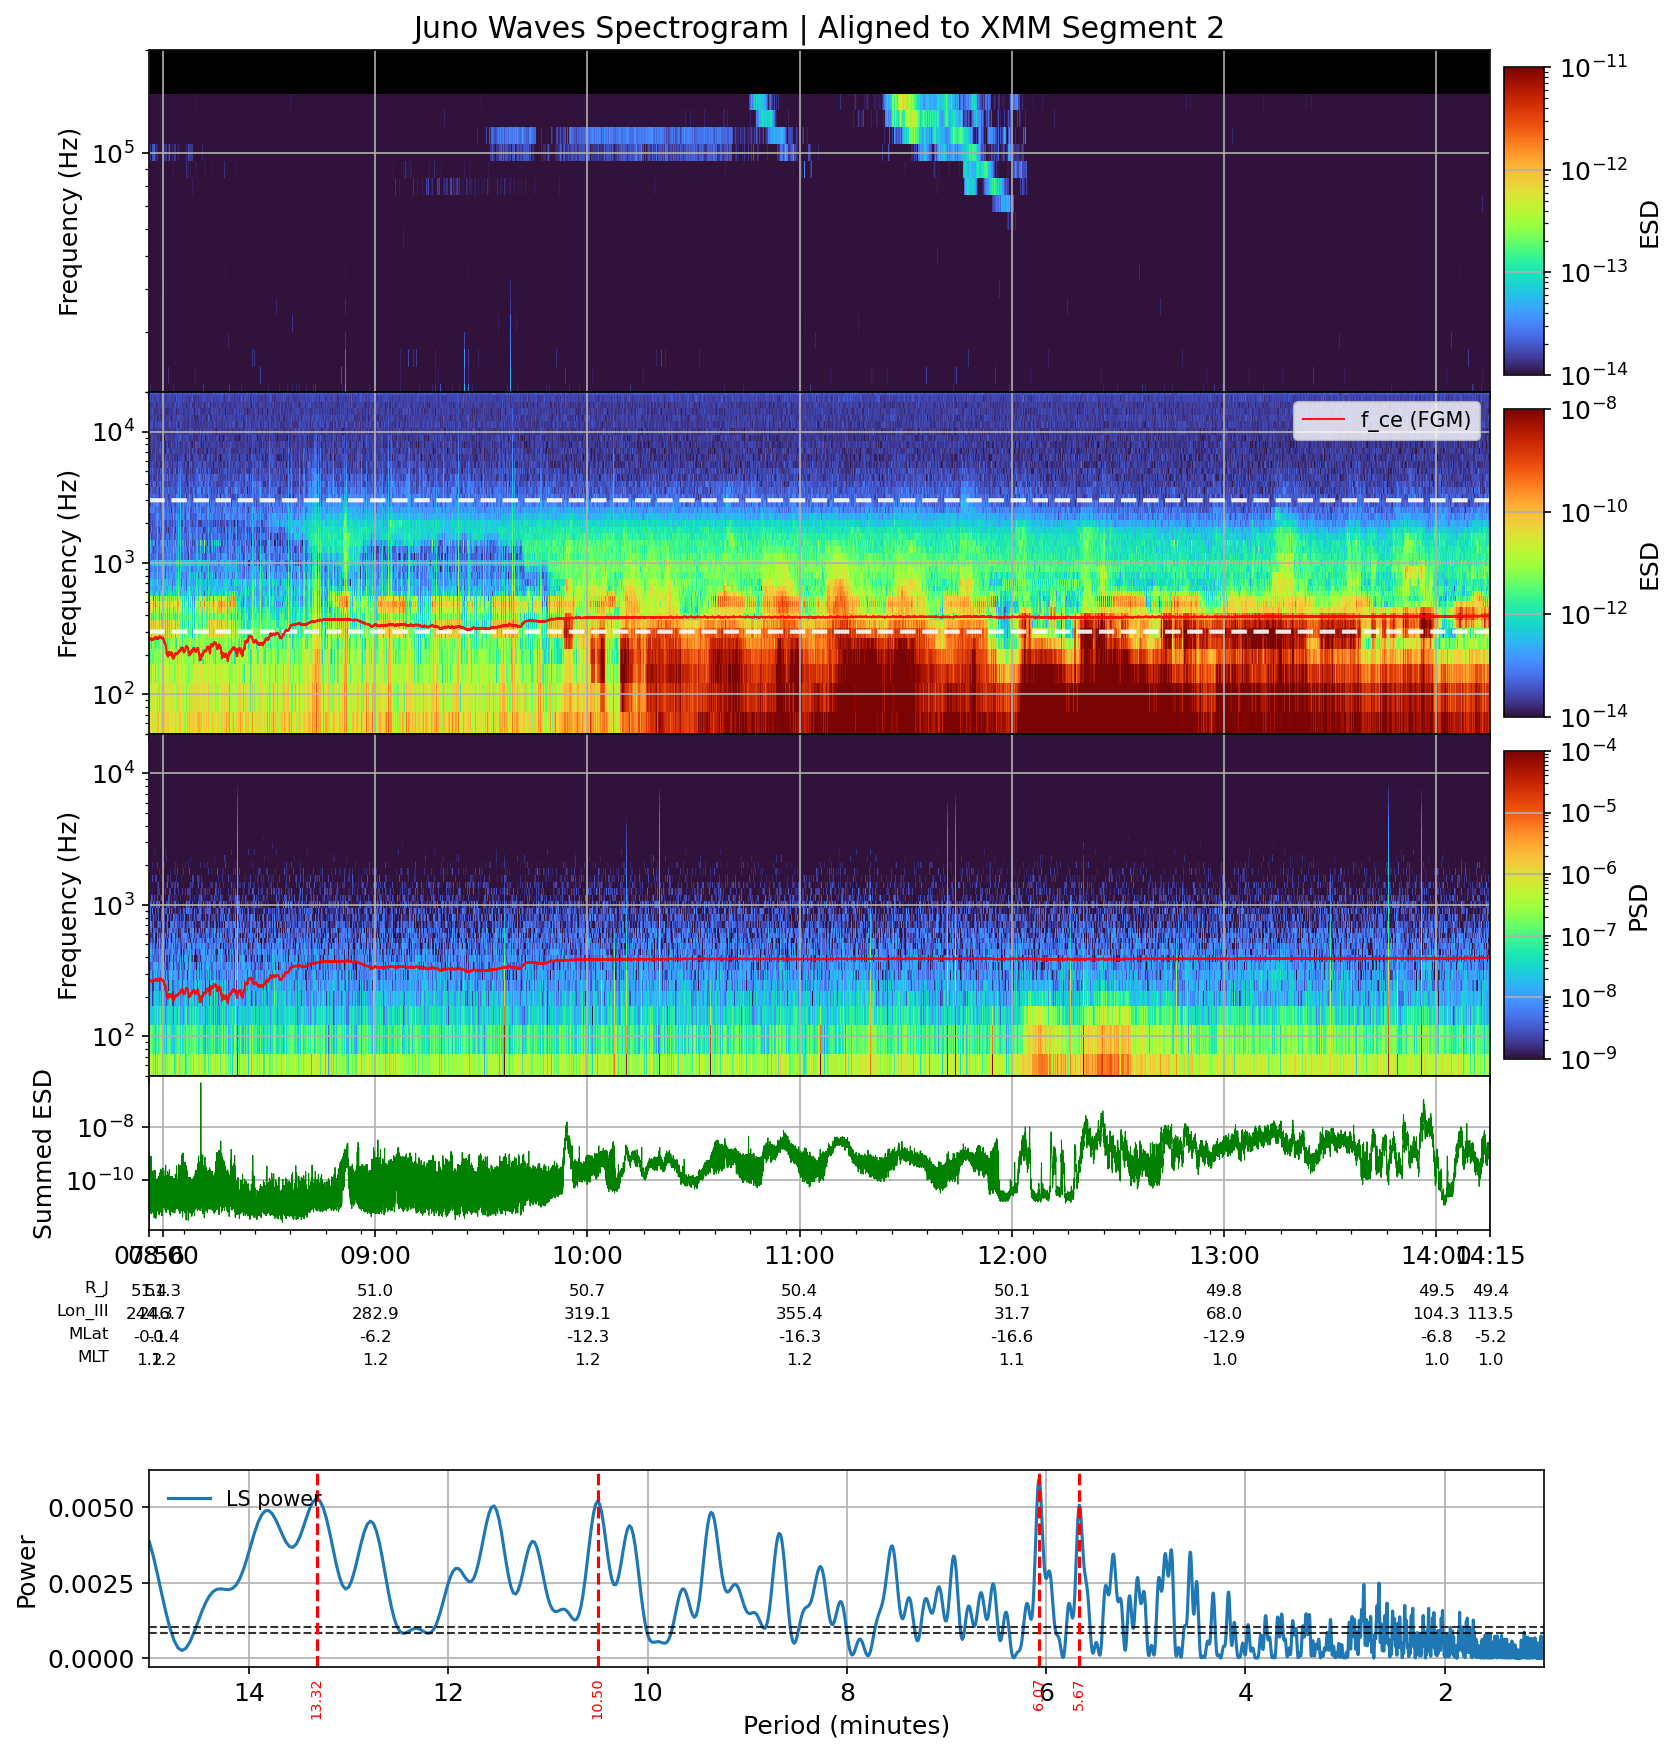


--- Processing XMM Segment 3 ---
Start Time (UTC) : 2019-04-02 17:51:15.574
End Time (UTC)   : 2019-04-02 22:16:35.574
Duration         : 4.42 hours
Dynamic Bin Size : 10.0s


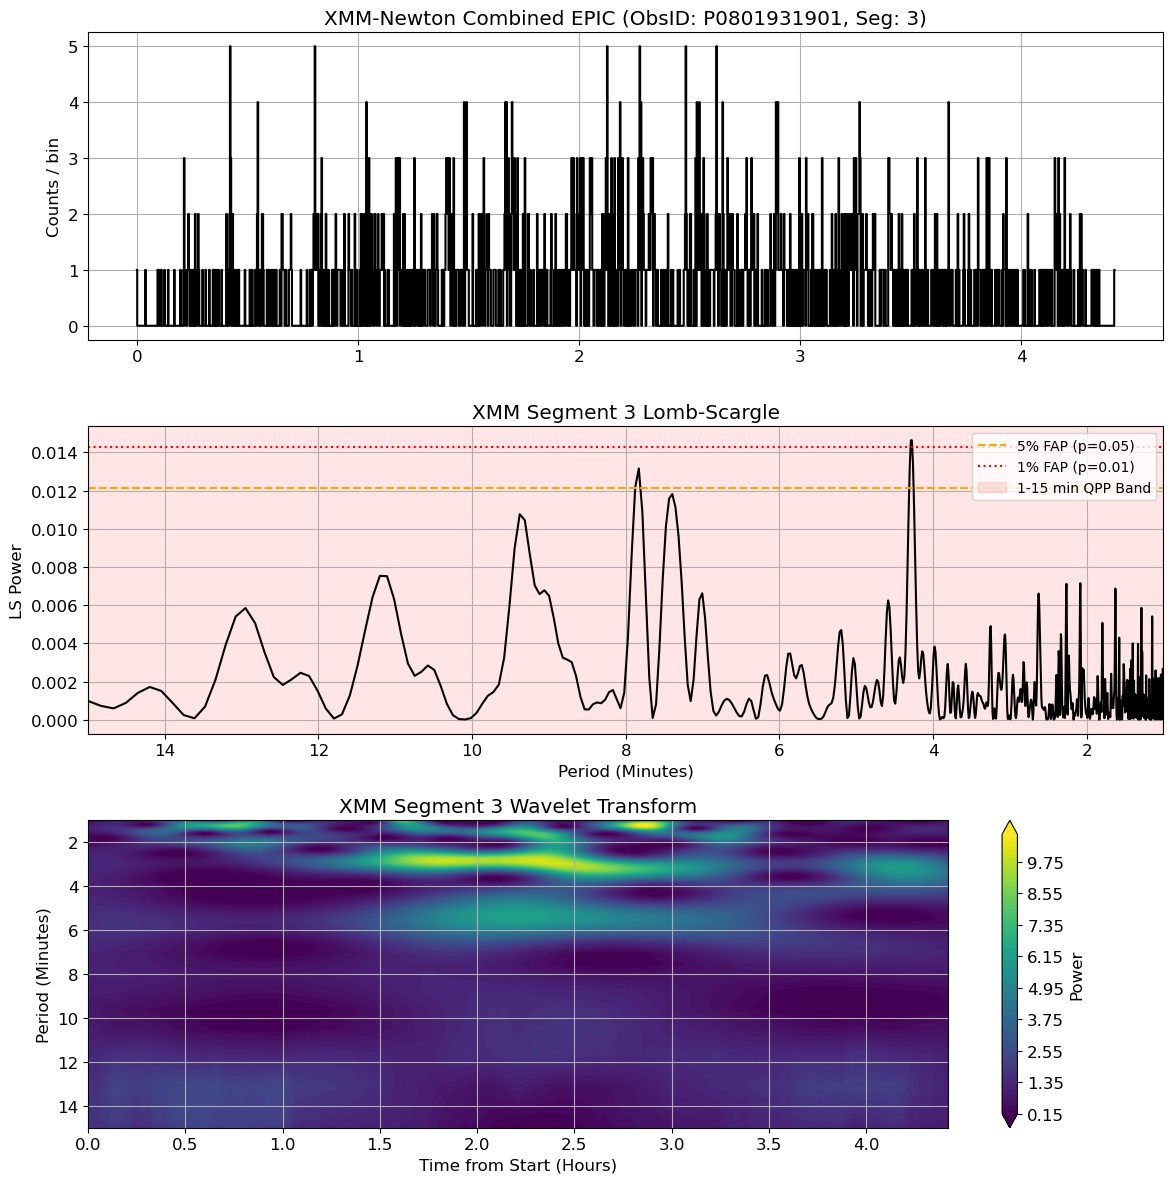

✔ [MATCH] Significant periodicities detected in XMM Segment 3! Proceeding to Das2 WAVES fetch...
Querying Das2 Time Range: 2019-04-02T17:51:15.574Z to 2019-04-02T22:16:35.574Z


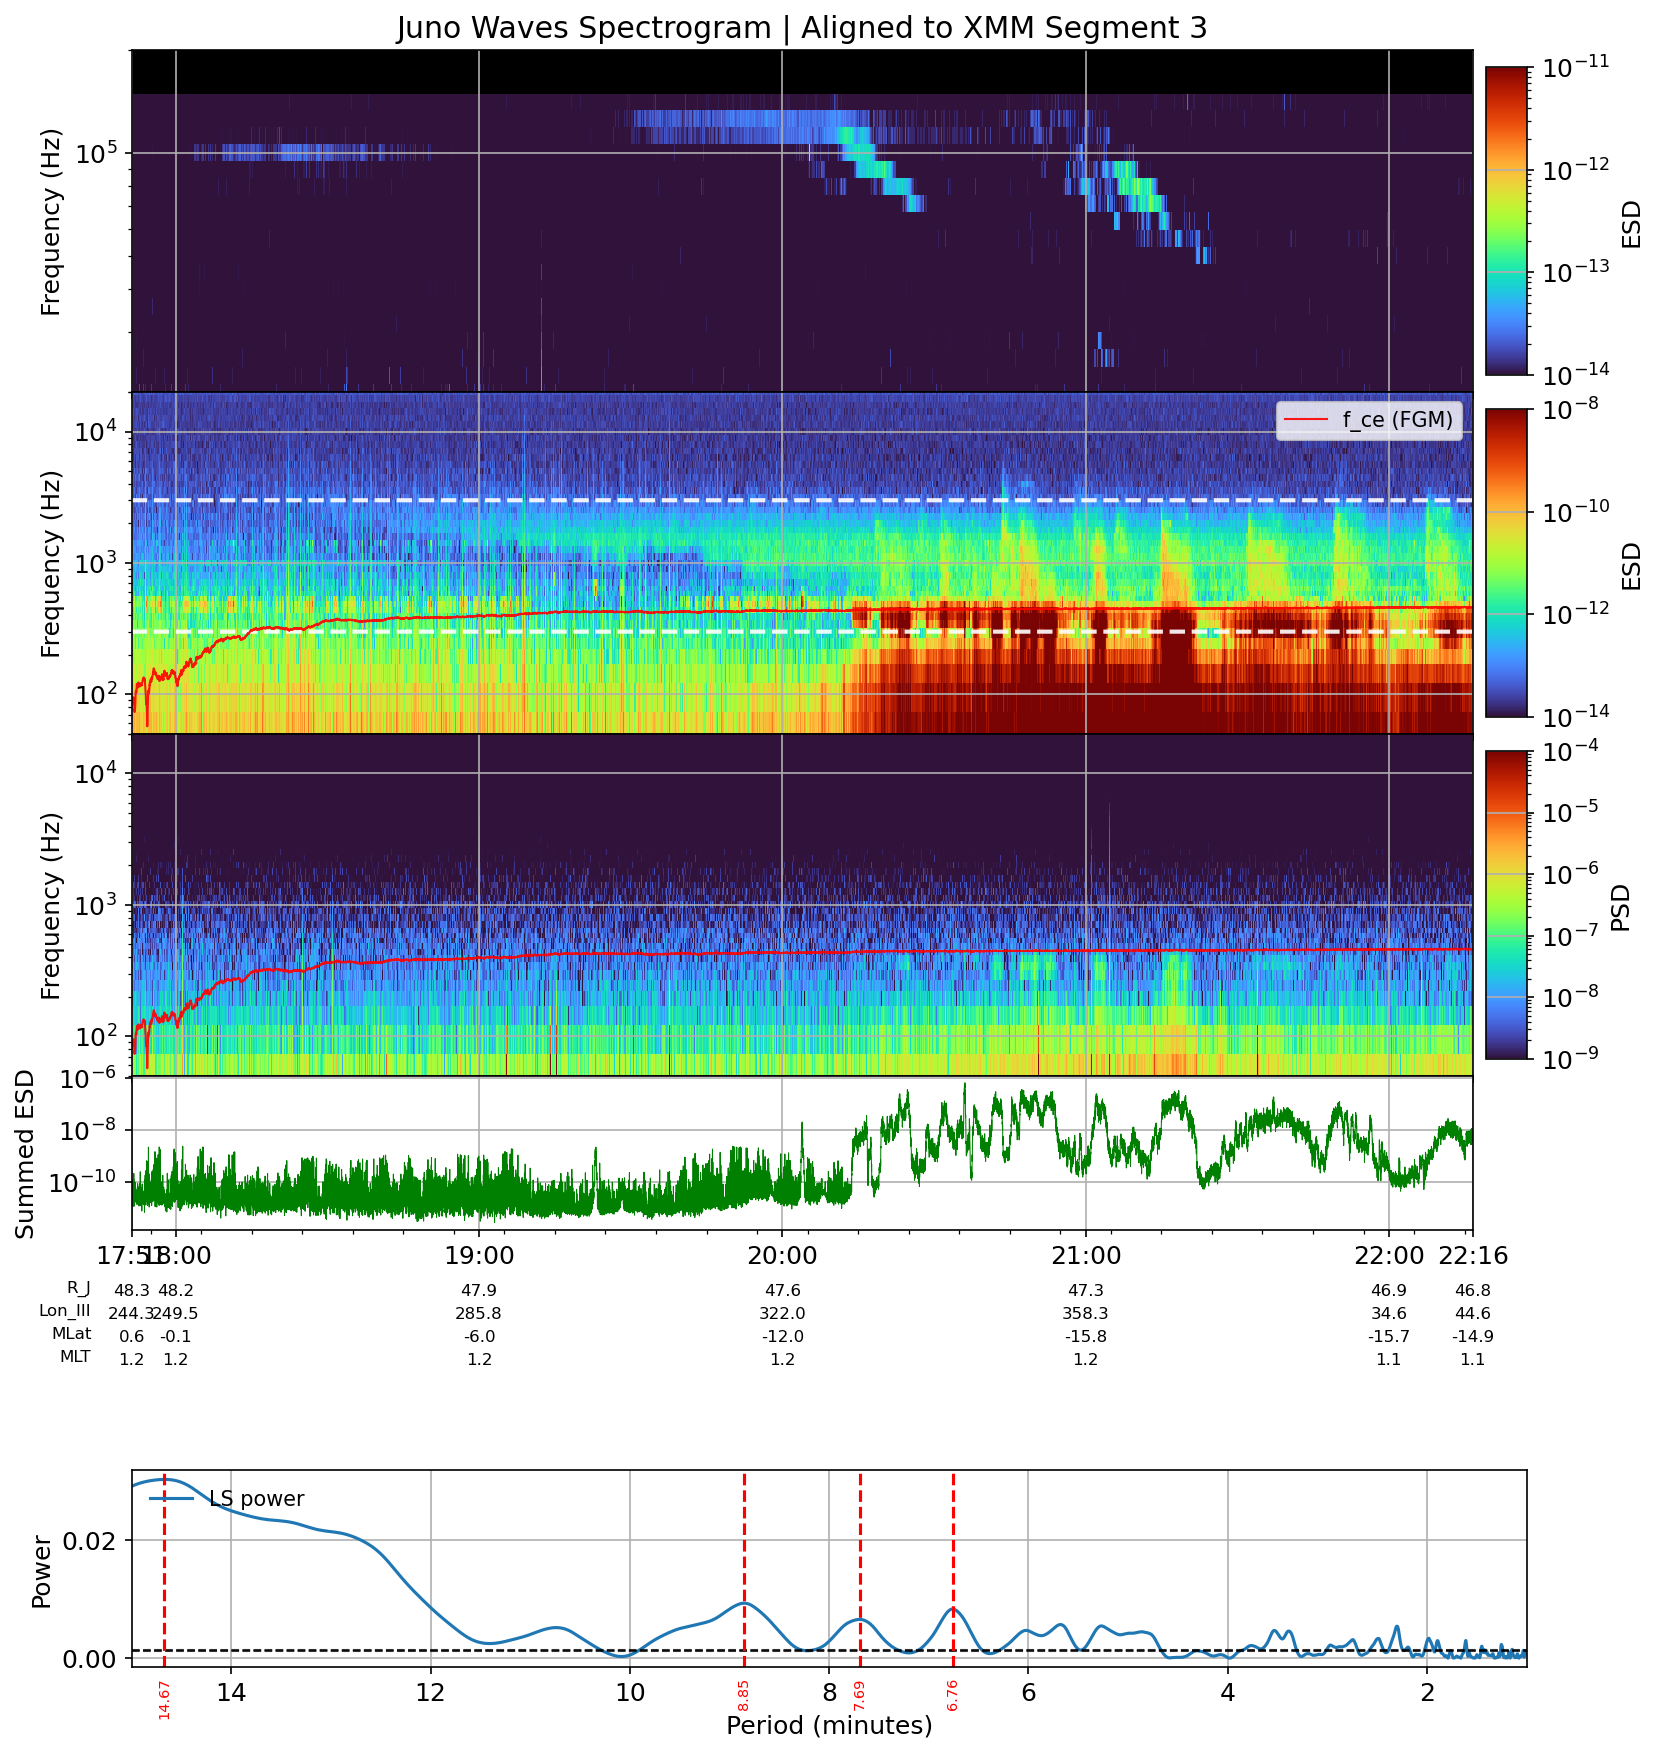

In [42]:

# --- Execution Loop ---
if __name__ == "__main__":
    all_segments = load_all_segments_xmm(xmm_files, gap_threshold_s=3600.0, base_bin=BIN_SIZE)

    for seg in all_segments:
        t_xmm = seg['t_binned']
        counts_xmm = seg['counts_binned']
        actual_bin_size = seg['bin_size']
        seg_id = seg['segment_id']
        
        # --- TWEAK: Calculate exact time period in UTC ---
        start_utc = Time(t_xmm[0], format='cxcsec').iso
        end_utc = Time(t_xmm[-1], format='cxcsec').iso
        duration_hrs = (t_xmm[-1] - t_xmm[0]) / 3600.0
        
        print(f"\n{'='*55}")
        print(f"--- Processing XMM Segment {seg_id} ---")
        print(f"Start Time (UTC) : {start_utc}")
        print(f"End Time (UTC)   : {end_utc}")
        print(f"Duration         : {duration_hrs:.2f} hours")
        print(f"Dynamic Bin Size : {actual_bin_size}s")
        print(f"{'='*55}")

        fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 12))

        t_hours = (t_xmm - t_xmm[0]) / 3600.0 
        ax1.plot(t_hours, counts_xmm, color='black', drawstyle='steps-mid')
        ax1.set_title(f'XMM-Newton Combined EPIC (ObsID: {XMM_OBS_ID}, Seg: {seg_id})')
        ax1.set_ylabel('Counts / bin')

        # 2. Lomb-Scargle & Significance Check (Replaces FFT)
        has_significant_qpp = compute_and_check_ls_xmm(t_xmm, counts_xmm, ax=ax2, title=f'XMM Segment {seg_id} Lomb-Scargle')

        # 3. Continuous Wavelet Transform
        compute_and_plot_cwt(t_xmm, counts_xmm, dt=actual_bin_size, ax=ax3, title=f'XMM Segment {seg_id} Wavelet Transform')

        plt.tight_layout()
        plt.show()

        # --- Conditional WAVES Fetching ---
        if not has_significant_qpp:
            print(f"✖ [SKIP] No statistically significant periodicities (p <= 0.05) detected in XMM Segment {seg_id}.")
            continue
            
        print(f"✔ [MATCH] Significant periodicities detected in XMM Segment {seg_id}! Proceeding to Das2 WAVES fetch...")

        # Convert segment bounds from cxcsec to standard Das2 ISO format with trailing Z
        start_time_iso = Time(t_xmm[0], format='cxcsec').isot + 'Z'
        end_time_iso = Time(t_xmm[-1], format='cxcsec').isot + 'Z'
        
        print(f"Querying Das2 Time Range: {start_time_iso} to {end_time_iso}")
        
        make_waves_segment(
            start_time=start_time_iso,
            end_time=end_time_iso,
            label=f"Aligned to XMM Segment {seg_id}",
            plot_fce=True,
            plot_b_panel=True
        )

--- Fetching Juno FGM Data for XMM Segment 1 ---
Window (UTC): 2019-04-01 23:21:56.399  -->  2019-04-02 04:18:56.399
[pds.peppi] Querying PDS4 Registry for host='urn:nasa:pds:context:instrument_host:spacecraft.jno', instrument='urn:nasa:pds:context:instrument:fgm.jno'...
[pds.peppi] No PDS4 observational table URLs returned for 2019-04-01 23:21:56.399 -> 2019-04-02 04:18:56.399.
[Fallback] Searching PDS-PPI JNO-J-3-FGM-CAL-V1.0 (PC 1-sec) archive...
Loading FGM file: https://pds-ppi.igpp.ucla.edu/data/JNO-J-3-FGM-CAL-V1.0/DATA/JUPITER/PC/PERI-19/fgm_jno_l3_2019091pc_r1s_v01.sts
Loading FGM file: https://pds-ppi.igpp.ucla.edu/data/JNO-J-3-FGM-CAL-V1.0/DATA/JUPITER/PC/PERI-19/fgm_jno_l3_2019092pc_r1s_v01.sts


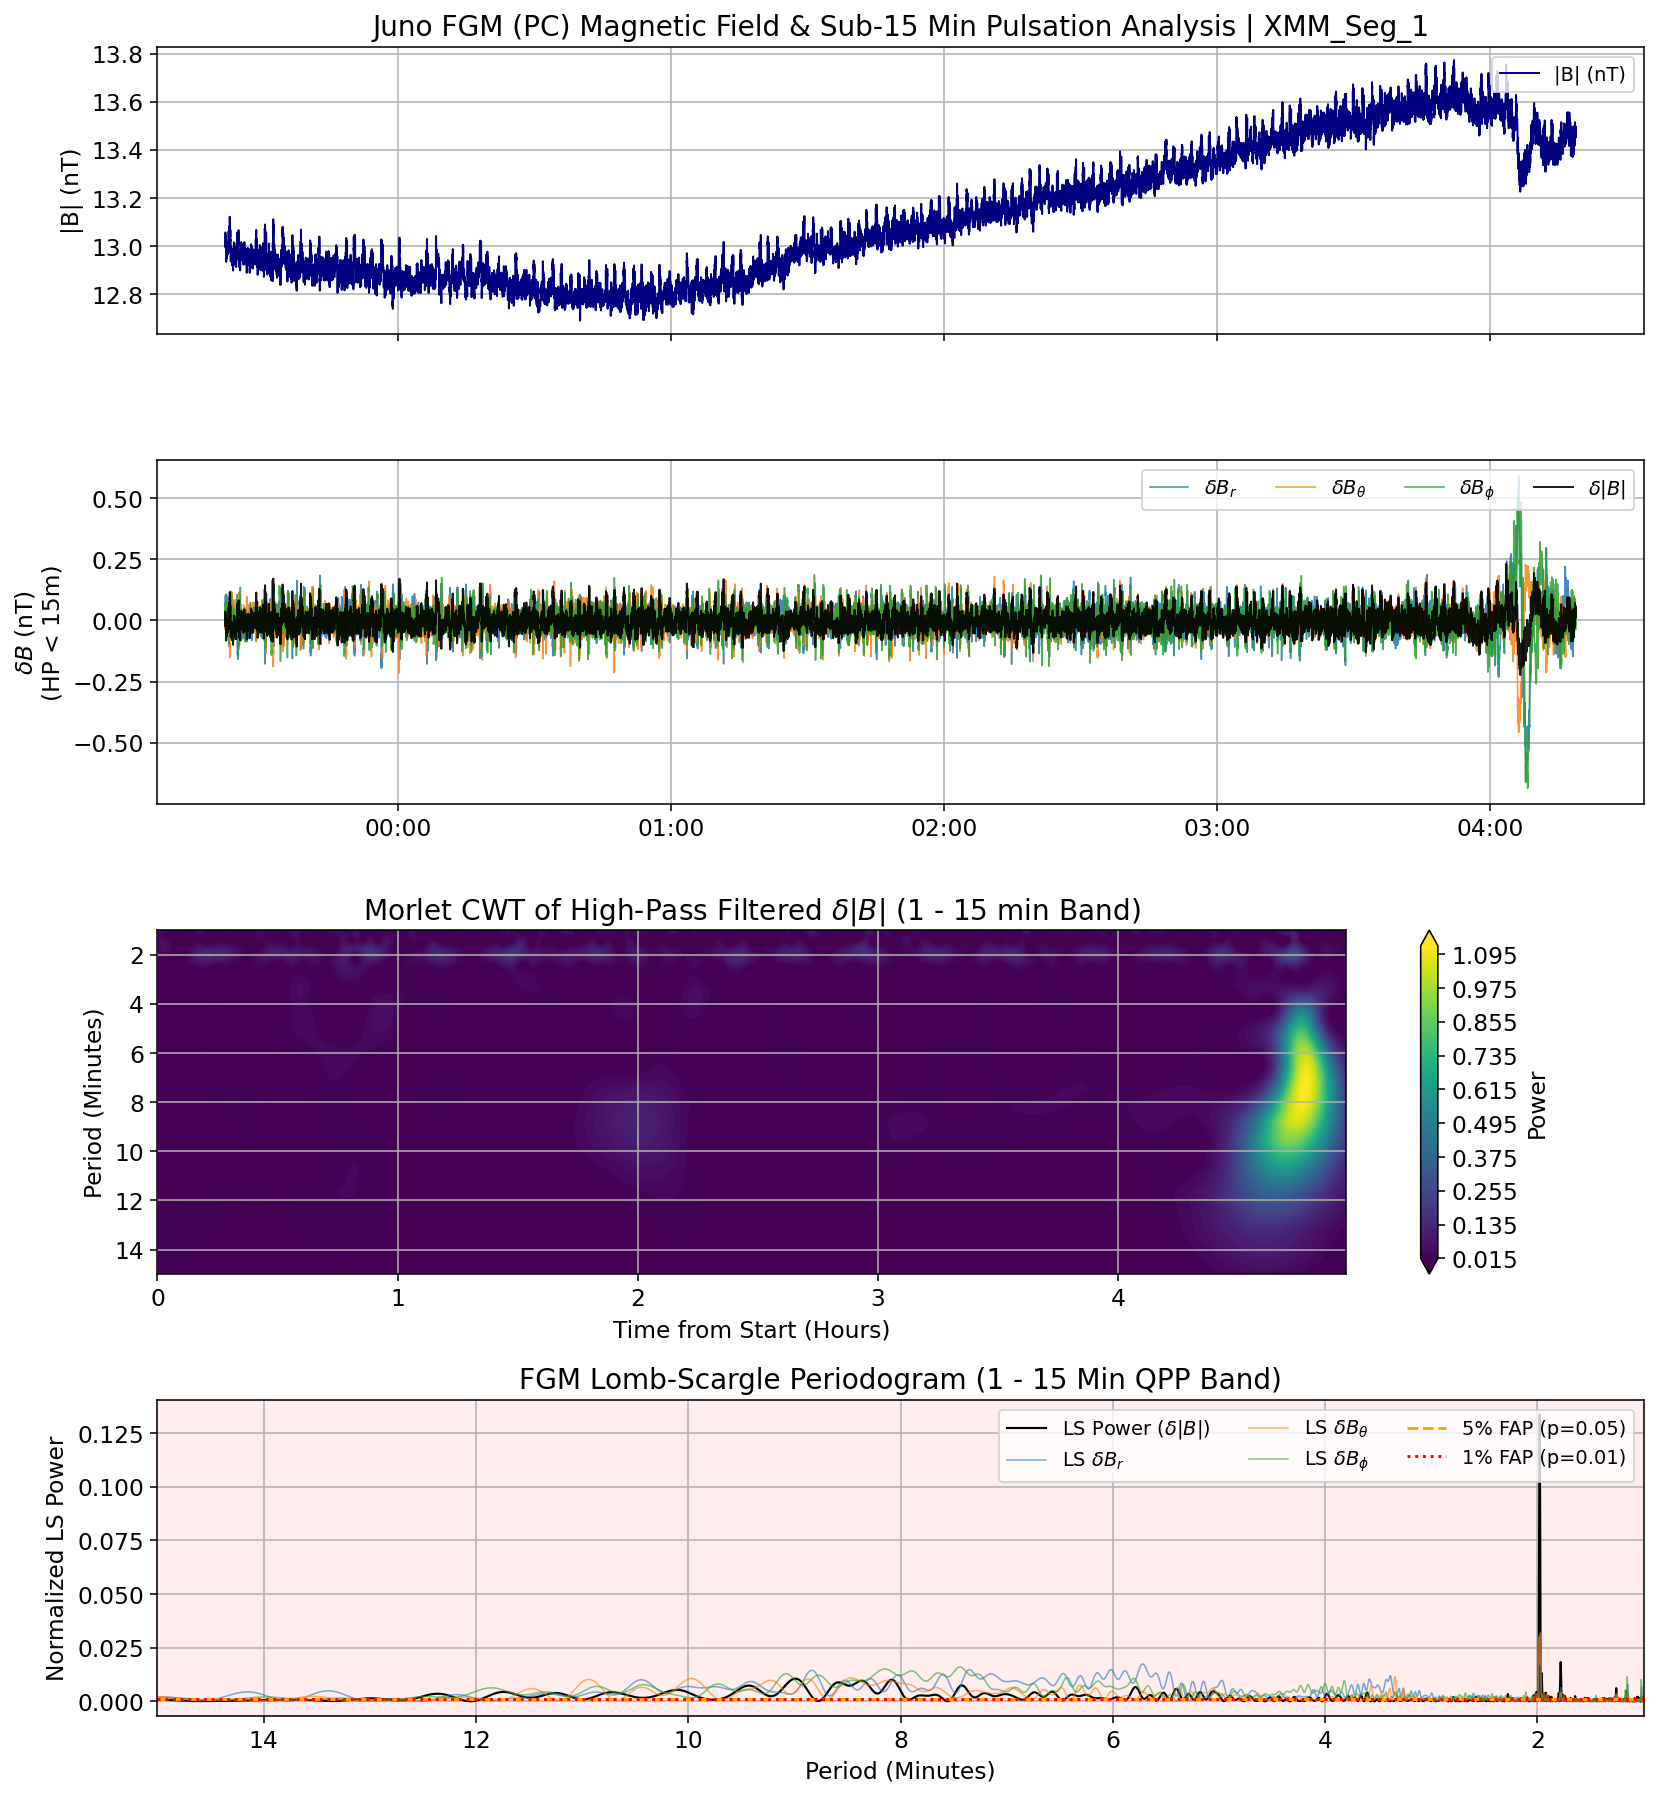

✔ [SIGNIFICANT] FGM |B| pulsation check (p <= 0.05) for XMM_Seg_1. Saved to FGM_FIGS/FGM_QPP_P0801931901_XMM_Seg_1.png

--- Fetching Juno FGM Data for XMM Segment 2 ---
Window (UTC): 2019-04-02 07:54:57.035  -->  2019-04-02 14:14:07.035
[pds.peppi] Querying PDS4 Registry for host='urn:nasa:pds:context:instrument_host:spacecraft.jno', instrument='urn:nasa:pds:context:instrument:fgm.jno'...
[pds.peppi] No PDS4 observational table URLs returned for 2019-04-02 07:54:57.035 -> 2019-04-02 14:14:07.035.
[Fallback] Searching PDS-PPI JNO-J-3-FGM-CAL-V1.0 (PC 1-sec) archive...
Loading FGM file: https://pds-ppi.igpp.ucla.edu/data/JNO-J-3-FGM-CAL-V1.0/DATA/JUPITER/PC/PERI-19/fgm_jno_l3_2019092pc_r1s_v01.sts


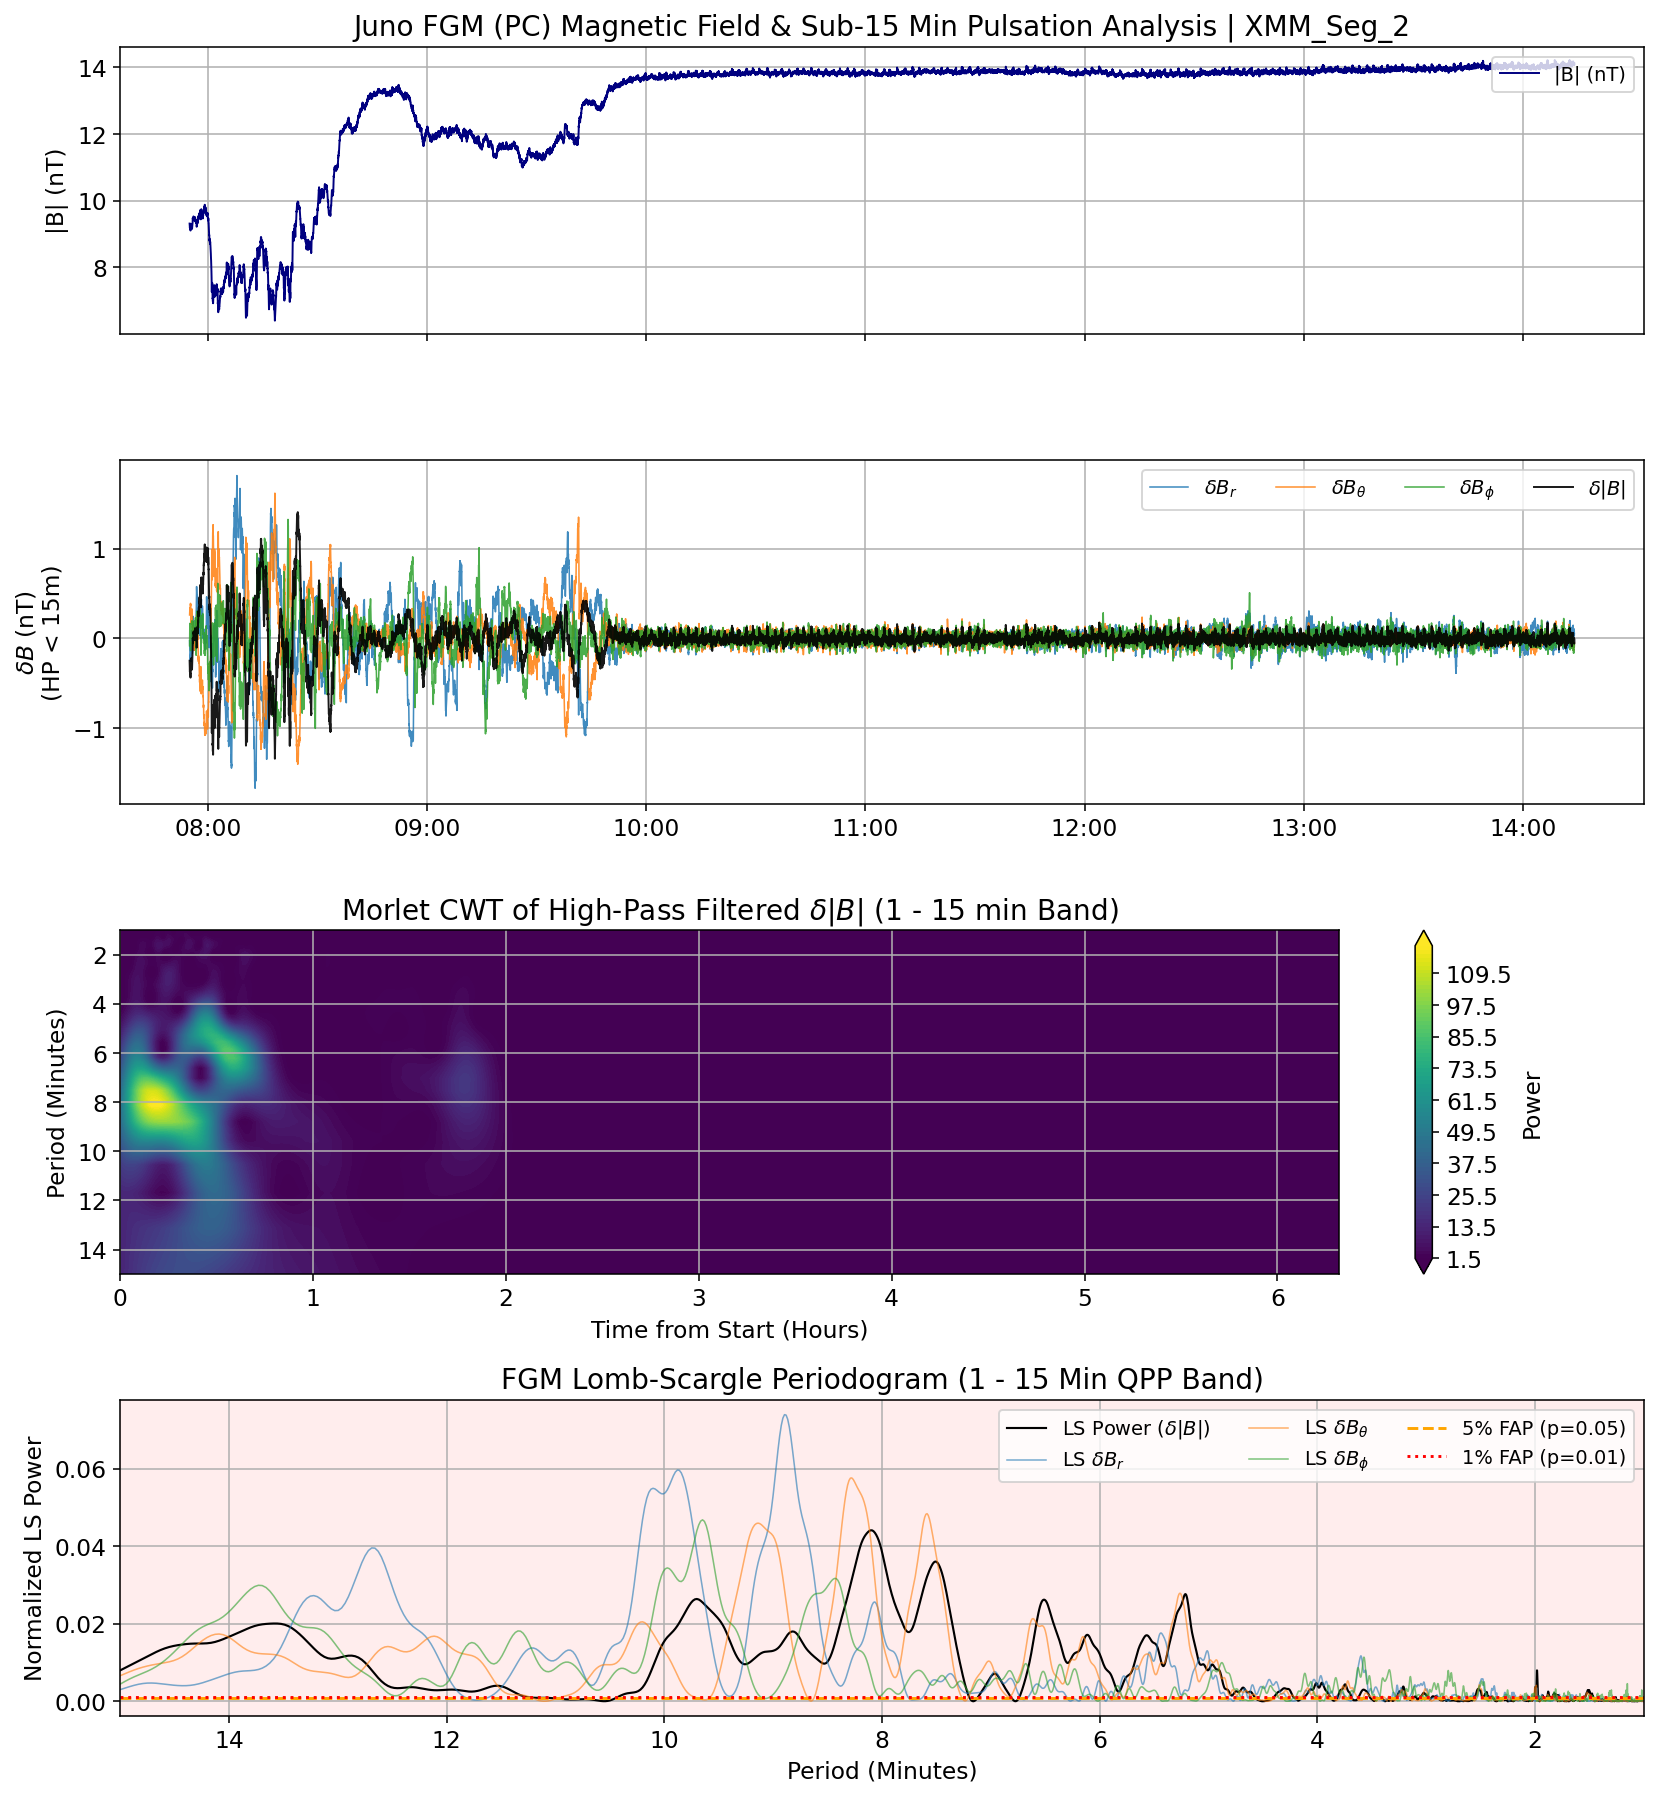

✔ [SIGNIFICANT] FGM |B| pulsation check (p <= 0.05) for XMM_Seg_2. Saved to FGM_FIGS/FGM_QPP_P0801931901_XMM_Seg_2.png

--- Fetching Juno FGM Data for XMM Segment 3 ---
Window (UTC): 2019-04-02 17:50:06.390  -->  2019-04-02 22:15:26.390
[pds.peppi] Querying PDS4 Registry for host='urn:nasa:pds:context:instrument_host:spacecraft.jno', instrument='urn:nasa:pds:context:instrument:fgm.jno'...
[pds.peppi] No PDS4 observational table URLs returned for 2019-04-02 17:50:06.390 -> 2019-04-02 22:15:26.390.
[Fallback] Searching PDS-PPI JNO-J-3-FGM-CAL-V1.0 (PC 1-sec) archive...
Loading FGM file: https://pds-ppi.igpp.ucla.edu/data/JNO-J-3-FGM-CAL-V1.0/DATA/JUPITER/PC/PERI-19/fgm_jno_l3_2019092pc_r1s_v01.sts


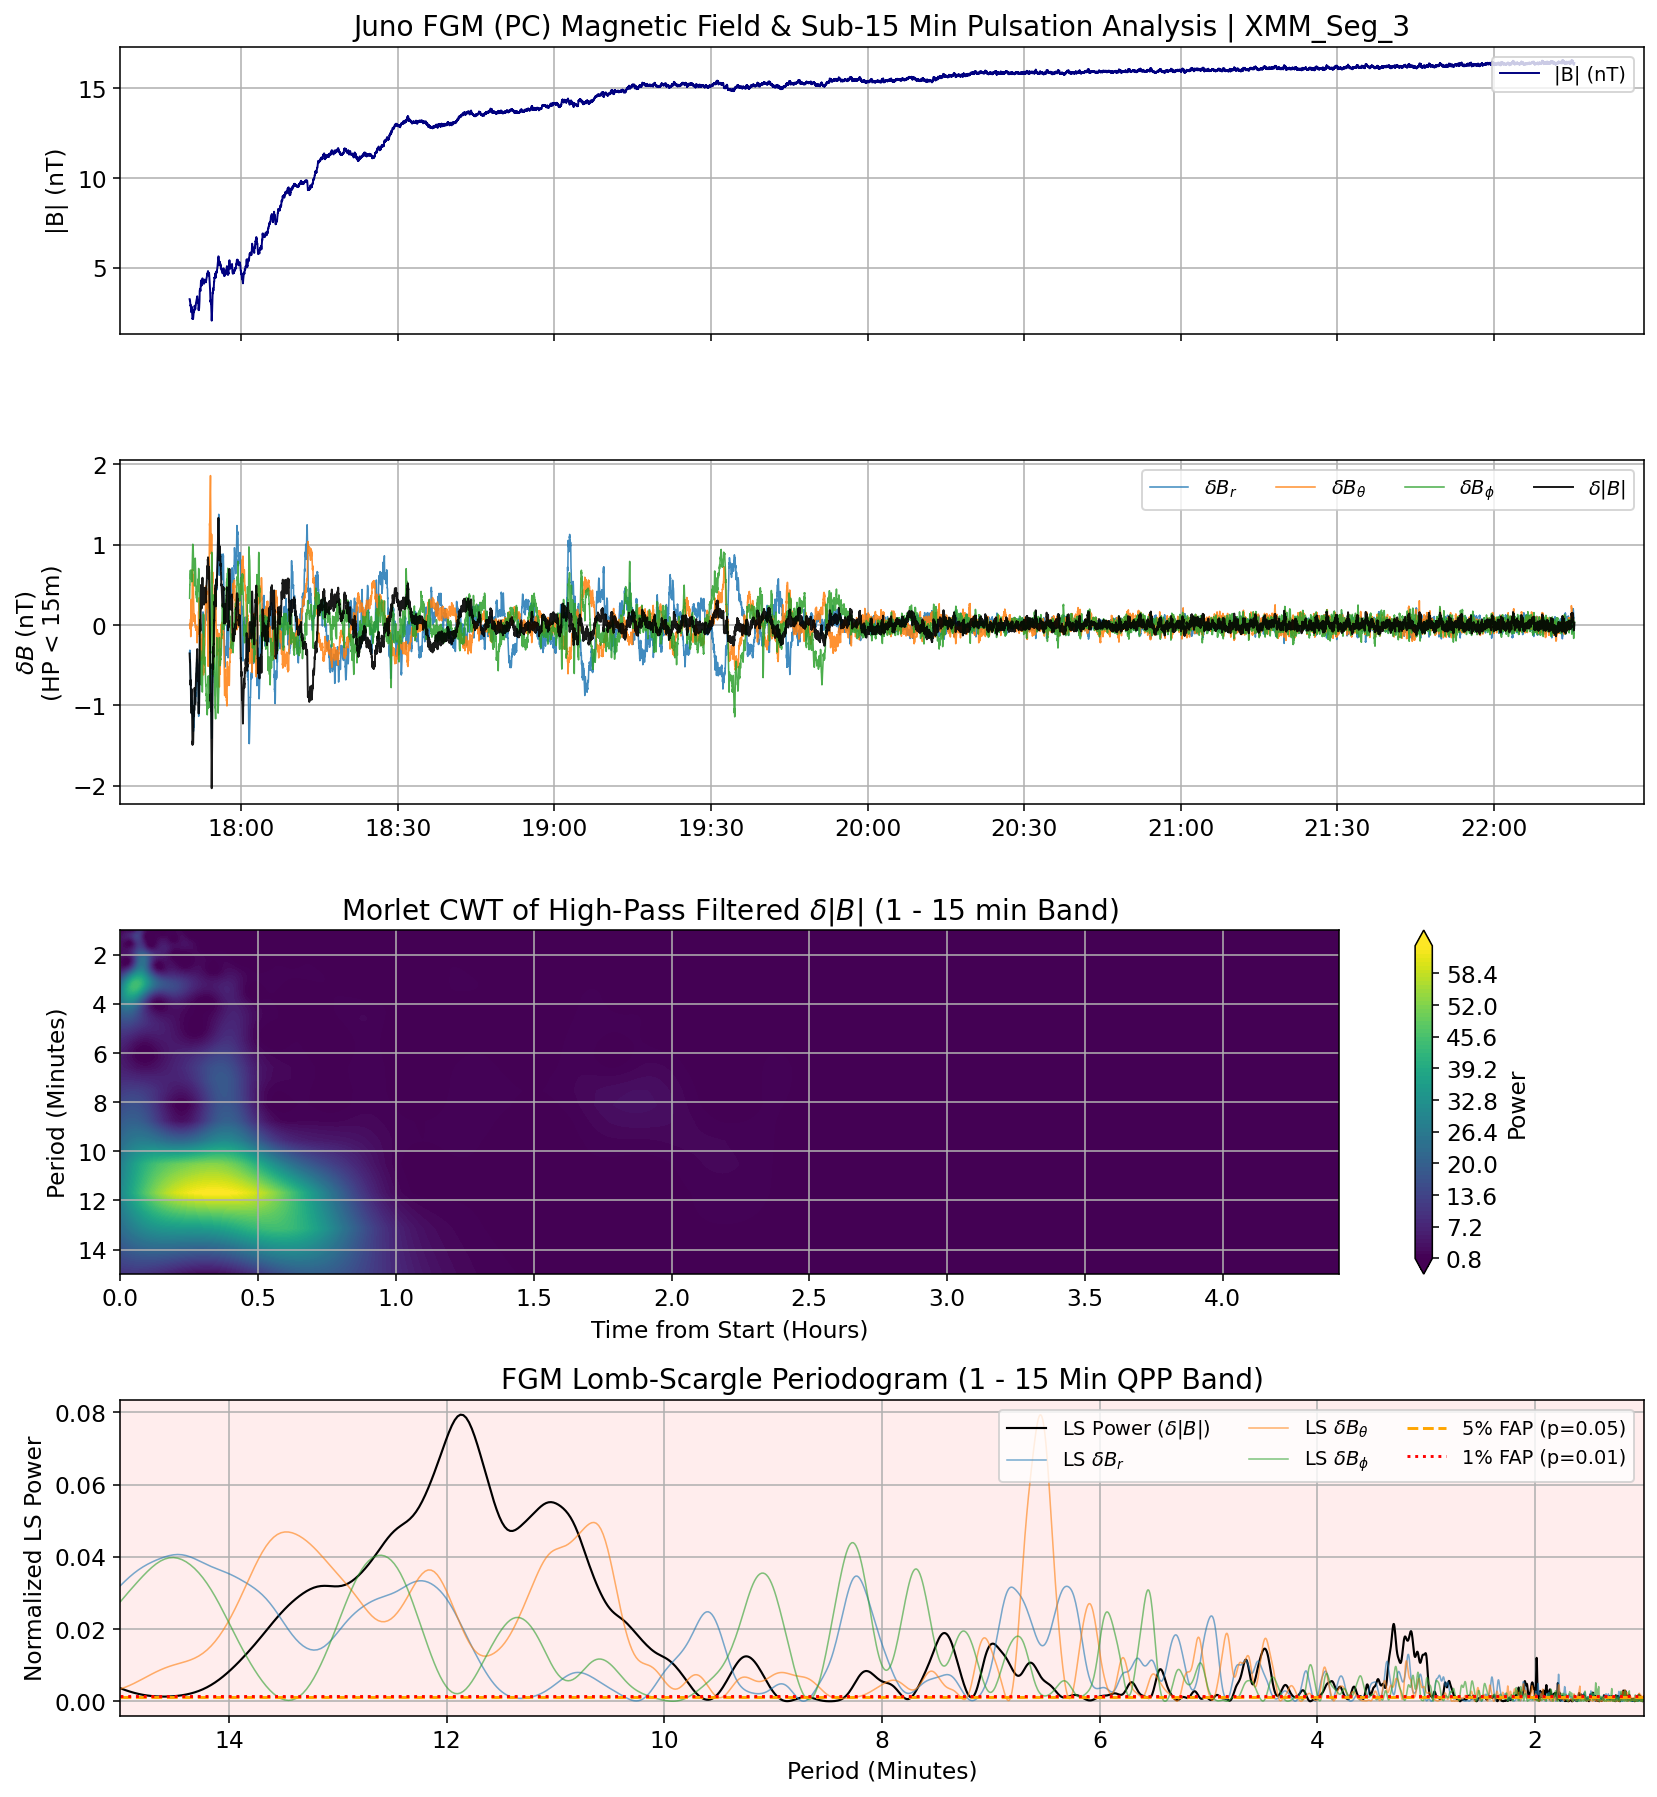

✔ [SIGNIFICANT] FGM |B| pulsation check (p <= 0.05) for XMM_Seg_3. Saved to FGM_FIGS/FGM_QPP_P0801931901_XMM_Seg_3.png



In [43]:
# --- JUNO MAG (FGM) Fetch & Sub-15 Min Pulsation Pipeline (via pds.peppi) ---
from datetime import datetime, timedelta
import io
import os
import re
import urllib.request
from astropy.time import Time
from astropy.timeseries import LombScargle
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.signal as signal

try:
    import pds.peppi as pep

    HAS_PEPPI = True
except ImportError:
    print("Warning: 'pds.peppi' is not installed. Run: pip install pds.peppi")
    HAS_PEPPI = False

FGM_FIG_OUTDIR = "FGM_FIGS"
os.makedirs(FGM_FIG_OUTDIR, exist_ok=True)


def query_juno_fgm_peppi(start_dt: datetime, end_dt: datetime):
    """Queries the NASA PDS4 Registry for Juno FGM observational products

    overlapping [start_dt, end_dt] using pds.peppi (compatible with both <0.9
    and >=0.9). Returns a list of data file URLs and a summary DataFrame of
    matched products.
    """
    if not HAS_PEPPI:
        return [], pd.DataFrame()

    # Standard NASA PDS4 Context LIDs for Juno and FGM
    juno_lid = "urn:nasa:pds:context:instrument_host:spacecraft.jno"
    fgm_lid = "urn:nasa:pds:context:instrument:fgm.jno"

    # Pad search window to day boundaries so daily FGM files overlapping the segment are caught
    search_start = datetime(
        start_dt.year, start_dt.month, start_dt.day, 0, 0, 0
    )
    search_end = datetime(
        end_dt.year, end_dt.month, end_dt.day, 23, 59, 59
    ) + timedelta(days=1)

    file_urls = []
    records = []

    try:
        client = pep.PDSRegistryClient()

        # Optional Context lookup if running pds.peppi >= 0.9.0
        if hasattr(pep, "Context"):
            ctx = pep.Context()
            if hasattr(ctx, "INSTRUMENT_HOSTS"):
                hosts = ctx.INSTRUMENT_HOSTS.search("juno")
                if hosts:
                    juno_lid = hosts[0].lid
            if hasattr(ctx, "INSTRUMENTS"):
                insts = [
                    i
                    for i in ctx.INSTRUMENTS.search("fgm")
                    if "jno" in str( getattr(i, "lid", "")).lower()
                ]
                if insts:
                    fgm_lid = insts[0].lid

        print(
            f"[pds.peppi] Querying PDS4 Registry for host='{juno_lid}',"
            f" instrument='{fgm_lid}'..."
        )
        q = pep.Products(client)

        # Chain filters safely across pds.peppi versions
        if hasattr(q, "has_instrument_host"):
            q = q.has_instrument_host(juno_lid)
        if hasattr(q, "has_instrument"):
            q = q.has_instrument(fgm_lid)
        elif hasattr(q, "has_target"):
            q = q.has_target("Jupiter")

        if hasattr(q, "after"):
            q = q.after(search_start)
        if hasattr(q, "before"):
            q = q.before(search_end)
        if hasattr(q, "observationals"):
            q = q.observationals()

        # Iterate over matched PDS4 products (cap at 200 to prevent runaway pagination if unfiltered)
        for idx, prod in enumerate(q):
            if idx >= 200:
                break
            prod_id = getattr(prod, "id", str(prod))
            props = getattr(prod, "properties", {})
            if not isinstance(props, dict):
                props = {}

            # If fallback target filter was used, ensure product belongs to Juno FGM
            if not hasattr(q, "has_instrument") and "fgm" not in prod_id.lower():
                continue

            refs = props.get("ops:Data_File_Info.ops:file_ref", [])
            if isinstance(refs, str):
                refs = [refs]
            data_refs = [
                r
                for r in refs
                if any(
                    r.lower().endswith(ext) for ext in (".tab", ".csv", ".sts")
                )
            ]
            file_urls.extend(data_refs)
            records.append({
                "id": prod_id,
                "start": props.get(
                    "pds:Time_Coordinates.pds:start_date_time", [None]
                )[0],
                "stop": props.get(
                    "pds:Time_Coordinates.pds:stop_date_time", [None]
                )[0],
                "file_refs": data_refs,
            })
    except Exception as e:
        print(f"[pds.peppi] Registry query warning: {e}")

    return file_urls, pd.DataFrame(records)


def parse_juno_fgm_sts(raw_text: str) -> pd.DataFrame:
    """Parses a Juno FGM calibrated ASCII (.sts / .tab) file into a DataFrame.

    Extracts UTC datetime, magnetic field vector components (B1, B2, B3 in nT),
    and computes total magnetic field magnitude |B|.
    """
    # Juno .sts files contain a PDS3/ASCII header ending at the final 'END_OBJECT'
    header_end = raw_text.rfind("END_OBJECT")
    if header_end != -1:
        newline_pos = raw_text.find("\n", header_end)
        data_str = raw_text[newline_pos + 1 :]
    else:
        data_str = raw_text

    # Standard Juno FGM columns:
    # YEAR DOY HOUR MIN SEC MSEC DECIMAL_DAY BX BY BZ [SC_POS_X SC_POS_Y SC_POS_Z]
    df = pd.read_csv(io.StringIO(data_str), sep=r"\s+", header=None)
    if df.shape[1] < 10:
        raise ValueError(f"Unexpected column count ({df.shape[1]}) in FGM table.")

    df = df.iloc[:, :10].copy()
    df.columns = [
        "YEAR",
        "DOY",
        "HOUR",
        "MIN",
        "SEC",
        "MSEC",
        "DEC_DAY",
        "B1",
        "B2",
        "B3",
    ]

    base_year = pd.to_datetime(df["YEAR"].astype(int).astype(str), format="%Y")
    dt_offset = (
        pd.to_timedelta(df["DOY"].astype(int) - 1, unit="D")
        + pd.to_timedelta(df["HOUR"].astype(int), unit="h")
        + pd.to_timedelta(df["MIN"].astype(int), unit="m")
        + pd.to_timedelta(df["SEC"].astype(int), unit="s")
        + pd.to_timedelta(df["MSEC"].astype(int), unit="ms")
    )
    df["Time"] = base_year + dt_offset

    # Mask PDS fill values (typically 99999.99)
    for col in ["B1", "B2", "B3"]:
        df.loc[df[col].abs() > 90000, col] = np.nan

    df["B_mag"] = np.sqrt(df["B1"] ** 2 + df["B2"] ** 2 + df["B3"] ** 2)
    return df.dropna(subset=["Time", "B_mag"]).reset_index(drop=True)


def fetch_fgm_pds_ppi_fallback(
    start_dt: datetime, end_dt: datetime, coord_sys: str = "PC", res: str = "r1s"
) -> list:
    """Fallback crawler for the NASA PDS-PPI HTTP archive (JNO-J-3-FGM-CAL-V1.0)

    when the requested perijove is stored in PDS3 .sts format and not yet in the
    PDS4 Registry.
    """
    base_url = f"https://pds-ppi.igpp.ucla.edu/data/JNO-J-3-FGM-CAL-V1.0/DATA/JUPITER/{coord_sys.upper()}/"
    cur_date = start_dt.date()
    target_ydoys = []
    while cur_date <= end_dt.date():
        target_ydoys.append(cur_date.strftime("%Y%j"))
        cur_date += timedelta(days=1)

    matched_urls = []
    try:
        with urllib.request.urlopen(base_url, timeout=15) as resp:
            html = resp.read().decode("utf-8", errors="ignore")
        peri_dirs = sorted(set(re.findall(r"PERI-\d+", html)))

        res_tag = f"_{res.lower()}" if res else ""
        for yJ in target_ydoys:
            fname_pattern = (
                rf"fgm_jno_l3_{yJ}{coord_sys.lower()}{res_tag}_v\d+\.sts"
            )
            for pdir in peri_dirs:
                dir_url = f"{base_url}{pdir}/"
                try:
                    with urllib.request.urlopen(dir_url, timeout=10) as dresp:
                        dhtml = dresp.read().decode("utf-8", errors="ignore")
                    matches = re.findall(fname_pattern, dhtml, flags=re.IGNORECASE)
                    if matches:
                        latest_file = sorted(set(matches))[-1]
                        matched_urls.append(f"{dir_url}{latest_file}")
                        break
                except Exception:
                    continue
    except Exception as e:
        print(f"[Fallback] Could not query PDS-PPI directory index: {e}")

    return matched_urls


def plot_fgm_cwt(
    time_sec: np.ndarray,
    data_array: np.ndarray,
    dt: float,
    ax,
    title: str = "Continuous Wavelet Transform (Morlet)",
):
    """Computes and plots the Morlet CWT (1 - 15 min band), compatible with both

    older SciPy (signal.cwt) and SciPy >= 1.15 (where signal.cwt was removed).
    """
    detrended = signal.detrend(np.nan_to_num(data_array))
    frequencies = np.linspace(1.0 / MAX_PERIOD_SEC, 1.0 / MIN_PERIOD_SEC, 100)
    w0 = 6.0
    widths = w0 / (2.0 * np.pi * frequencies * dt)

    if hasattr(signal, "cwt") and hasattr(signal, "morlet2"):
        cwtm = signal.cwt(detrended, signal.morlet2, widths, w=w0)
    else:
        # Direct Morlet convolution fallback for SciPy >= 1.15
        cwtm = np.zeros((len(widths), len(detrended)), dtype=np.complex128)
        for idx, width in enumerate(widths):
            N_wav = min(int(10 * width), len(detrended))
            if N_wav % 2 == 0:
                N_wav += 1
            t_wav = np.arange(-(N_wav // 2), N_wav // 2 + 1, dtype=float)
            wav = (
                np.pi ** (-0.25)
                * np.sqrt(1.0 / width)
                * np.exp(1j * w0 * t_wav / width)
                * np.exp(-0.5 * (t_wav / width) ** 2)
            )
            cwtm[idx, :] = signal.fftconvolve(
                detrended, np.conj(wav[::-1]), mode="same"
            )

    power = np.abs(cwtm) ** 2
    t_hours = (time_sec - time_sec[0]) / 3600.0
    periods_min = (1.0 / frequencies) / 60.0
    T, P = np.meshgrid(t_hours, periods_min)

    c = ax.contourf(T, P, power, 80, cmap="viridis", extend="both")
    ax.set_ylabel("Period (Minutes)")
    ax.set_xlabel("Time from Start (Hours)")
    ax.set_title(title)
    ax.set_ylim(MAX_PERIOD_SEC / 60.0, MIN_PERIOD_SEC / 60.0)
    plt.colorbar(c, ax=ax, label="Power")


def analyze_fgm_segment(
    start_time_str: str,
    end_time_str: str,
    label: str = "Segment",
    coord_sys: str = "PC",
    period_min: float = MIN_PERIOD_SEC / 60.0,
    period_max: float = MAX_PERIOD_SEC / 60.0,
    ls_nfreq: int = 5000,
):
    """Fetches Juno FGM data for [start_time_str, end_time_str] using pds.peppi

    (with automatic PDS-PPI fallback), high-pass filters the magnetic field, and
    tests for sub-15 minute pulsations using Lomb-Scargle and Morlet CWT.
    """
    t_start = Time(start_time_str, format="iso", scale="utc")
    t_end = Time(end_time_str, format="iso", scale="utc")
    start_dt, end_dt = t_start.to_datetime(), t_end.to_datetime()

    # 1. Query via pds.peppi
    file_urls, df_meta = query_juno_fgm_peppi(start_dt, end_dt)
    if not df_meta.empty:
        print(f"[pds.peppi] Found {len(df_meta)} PDS4 product(s):")
        display(df_meta[["id", "start", "stop"]].head(10))

    # 2. Fallback to PDS-PPI direct archive if PDS4 registry has no observational tables for this date
    if not file_urls:
        print(
            "[pds.peppi] No PDS4 observational table URLs returned for"
            f" {start_time_str} -> {end_time_str}."
        )
        print(
            "[Fallback] Searching PDS-PPI JNO-J-3-FGM-CAL-V1.0"
            f" ({coord_sys} 1-sec) archive..."
        )
        file_urls = fetch_fgm_pds_ppi_fallback(
            start_dt, end_dt, coord_sys=coord_sys, res="r1s"
        )

    if not file_urls:
        print(f"No FGM files found for {label}. Skipping.")
        return None

    # 3. Download and parse FGM data tables
    dfs = []
    for url in file_urls:
        print(f"Loading FGM file: {url}")
        with urllib.request.urlopen(url, timeout=30) as resp:
            raw_text = resp.read().decode("utf-8", errors="ignore")
        dfs.append(parse_juno_fgm_sts(raw_text))

    df_fgm = (
        pd.concat(dfs, ignore_index=True)
        .sort_values("Time")
        .drop_duplicates("Time")
    )

    # Slice to exact XMM segment window
    mask = (df_fgm["Time"] >= start_dt) & (df_fgm["Time"] <= end_dt)
    df_seg = df_fgm.loc[mask].copy().reset_index(drop=True)

    if df_seg.empty:
        print(
            "Warning: FGM file(s) loaded, but no samples fall inside"
            f" {start_time_str} - {end_time_str}."
        )
        return None

    # 4. High-pass filter (cutoff at MAX_PERIOD_SEC = 900s) to remove background Jovian field gradient
    times = df_seg["Time"].to_numpy(dtype="datetime64[ms]")
    t_sec = (times - times[0]) / np.timedelta64(1, "s")
    dt_med = float(np.nanmedian(np.diff(t_sec)))

    fs = 1.0 / dt_med
    sos = signal.butter(
        4, 1.0 / MAX_PERIOD_SEC, btype="highpass", fs=fs, output="sos"
    )

    df_seg["B1_filt"] = signal.sosfiltfilt(sos, df_seg["B1"].to_numpy())
    df_seg["B2_filt"] = signal.sosfiltfilt(sos, df_seg["B2"].to_numpy())
    df_seg["B3_filt"] = signal.sosfiltfilt(sos, df_seg["B3"].to_numpy())
    df_seg["Bmag_filt"] = signal.sosfiltfilt(sos, df_seg["B_mag"].to_numpy())

    # 5. Lomb-Scargle Periodogram on filtered |B| and components (1 - 15 min band)
    fmin, fmax = 1.0 / (period_max * 60.0), 1.0 / (period_min * 60.0)
    freqs_ls = np.linspace(fmin, fmax, ls_nfreq)
    periods_min = (1.0 / freqs_ls) / 60.0

    ls_bmag = LombScargle(
        t_sec, df_seg["Bmag_filt"], normalization="standard"
    )
    power_bmag = ls_bmag.power(freqs_ls)
    try:
        fap_05 = ls_bmag.false_alarm_level(
            0.05, method="baluev", minimum_frequency=fmin, maximum_frequency=fmax
        )
        fap_01 = ls_bmag.false_alarm_level(
            0.01, method="baluev", minimum_frequency=fmin, maximum_frequency=fmax
        )
    except Exception:
        fap_05 = ls_bmag.false_alarm_level(
            0.05, method="naive", minimum_frequency=fmin, maximum_frequency=fmax
        )
        fap_01 = ls_bmag.false_alarm_level(
            0.01, method="naive", minimum_frequency=fmin, maximum_frequency=fmax
        )

    # 6. Plotting: Raw |B|, High-Pass Filtered dB Components, Morlet CWT, and Lomb-Scargle Periodogram
    comp_labels = (
        (r"$B_r$", r"$B_\theta$", r"$B_\phi$")
        if coord_sys.upper() == "PC"
        else (r"$B_x$", r"$B_y$", r"$B_z$")
    )

    fig, axes = plt.subplots(
        4,
        1,
        figsize=(12, 13),
        dpi=140,
        gridspec_kw={"height_ratios": [1, 1.2, 1.2, 1.1]},
    )
    ax_raw, ax_filt, ax_cwt, ax_ls = axes

    # Panel 1: Background |B| Magnitude
    ax_raw.plot(times, df_seg["B_mag"], color="navy", lw=1.0, label="|B| (nT)")
    ax_raw.set_ylabel("|B| (nT)")
    ax_raw.set_title(
        f"Juno FGM ({coord_sys.upper()}) Magnetic Field & Sub-15 Min Pulsation"
        f" Analysis | {label}"
    )
    ax_raw.legend(loc="upper right", fontsize="small")
    ax_raw.tick_params(labelbottom=False)

    # Panel 2: High-Pass Filtered dB Perturbations (< 15 min)
    ax_filt.plot(
        times,
        df_seg["B1_filt"],
        lw=0.8,
        alpha=0.85,
        label=rf"$\delta${comp_labels[0]}",
    )
    ax_filt.plot(
        times,
        df_seg["B2_filt"],
        lw=0.8,
        alpha=0.85,
        label=rf"$\delta${comp_labels[1]}",
    )
    ax_filt.plot(
        times,
        df_seg["B3_filt"],
        lw=0.8,
        alpha=0.85,
        label=rf"$\delta${comp_labels[2]}",
    )
    ax_filt.plot(
        times,
        df_seg["Bmag_filt"],
        color="k",
        lw=1.0,
        alpha=0.9,
        label=r"$\delta |B|$",
    )
    ax_filt.set_ylabel(r"$\delta B$ (nT)" + "\n(HP < 15m)")
    ax_filt.legend(loc="upper right", ncols=4, fontsize="small")
    ax_filt.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))

    # Panel 3: Morlet Continuous Wavelet Transform of d|B|
    plot_fgm_cwt(
        t_sec,
        df_seg["Bmag_filt"].to_numpy(),
        dt_med,
        ax_cwt,
        title=r"Morlet CWT of High-Pass Filtered $\delta |B|$ (1 - 15 min Band)",
    )

    # Panel 4: Lomb-Scargle Periodogram (1 - 15 min QPP Band)
    ax_ls.plot(
        periods_min,
        power_bmag,
        color="k",
        lw=1.1,
        label=r"LS Power ($\delta |B|$)",
    )
    for col, clab, col_c in zip(
        ["B1_filt", "B2_filt", "B3_filt"],
        comp_labels,
        ["tab:blue", "tab:orange", "tab:green"],
    ):
        ls_c = LombScargle(t_sec, df_seg[col], normalization="standard")
        ax_ls.plot(
            periods_min,
            ls_c.power(freqs_ls),
            lw=0.8,
            alpha=0.6,
            color=col_c,
            label=rf"LS $\delta${clab}",
        )

    ax_ls.axhline(fap_05, color="orange", ls="--", label="5% FAP (p=0.05)")
    ax_ls.axhline(fap_01, color="red", ls=":", label="1% FAP (p=0.01)")
    ax_ls.set_xlim(period_max, period_min)
    ax_ls.set_xlabel("Period (Minutes)")
    ax_ls.set_ylabel("Normalized LS Power")
    ax_ls.set_title("FGM Lomb-Scargle Periodogram (1 - 15 Min QPP Band)")
    ax_ls.axvspan(period_min, period_max, color="red", alpha=0.07)
    ax_ls.legend(loc="upper right", ncols=3, fontsize="small")

    plt.tight_layout()
    out_path = os.path.join(
        FGM_FIG_OUTDIR, f"FGM_QPP_{XMM_OBS_ID}_{label.replace(' ', '_')}.png"
    )
    plt.savefig(out_path, dpi=150)
    plt.show()

    is_sig = bool(np.any(power_bmag > fap_05))
    status = "✔ [SIGNIFICANT]" if is_sig else "✖ [NO SIGNIFICANT PEAK]"
    print(
        f"{status} FGM |B| pulsation check (p <= 0.05) for {label}. Saved to"
        f" {out_path}\n"
    )
    return df_seg


# --- Run FGM Pipeline Across All Loaded XMM Segments ---
segments_xmm = load_all_segments_xmm(xmm_files, base_bin=BIN_SIZE)

fgm_results = {}
for seg in segments_xmm:
    seg_id = seg["segment_id"]
    t_b = seg["t_binned"]

    # Convert light-time corrected XMM cxcsec segment bounds to ISO UTC strings
    t_start_iso = Time(t_b[0], format="cxcsec", scale="tt").utc.iso
    t_end_iso = Time(t_b[-1], format="cxcsec", scale="tt").utc.iso

    print("=" * 60)
    print(f"--- Fetching Juno FGM Data for XMM Segment {seg_id} ---")
    print(f"Window (UTC): {t_start_iso}  -->  {t_end_iso}")
    print("=" * 60)

    fgm_results[seg_id] = analyze_fgm_segment(
        start_time_str=t_start_iso,
        end_time_str=t_end_iso,
        label=f"XMM_Seg_{seg_id}",
        coord_sys="PC",  # Options: 'PC' (Planetocentric), 'SS' (Sun-State), 'PL' (Payload)
    )

[WAVES Fetch Warning] Could not load WAVES ESD: could not convert string to float: '2019-04-01'


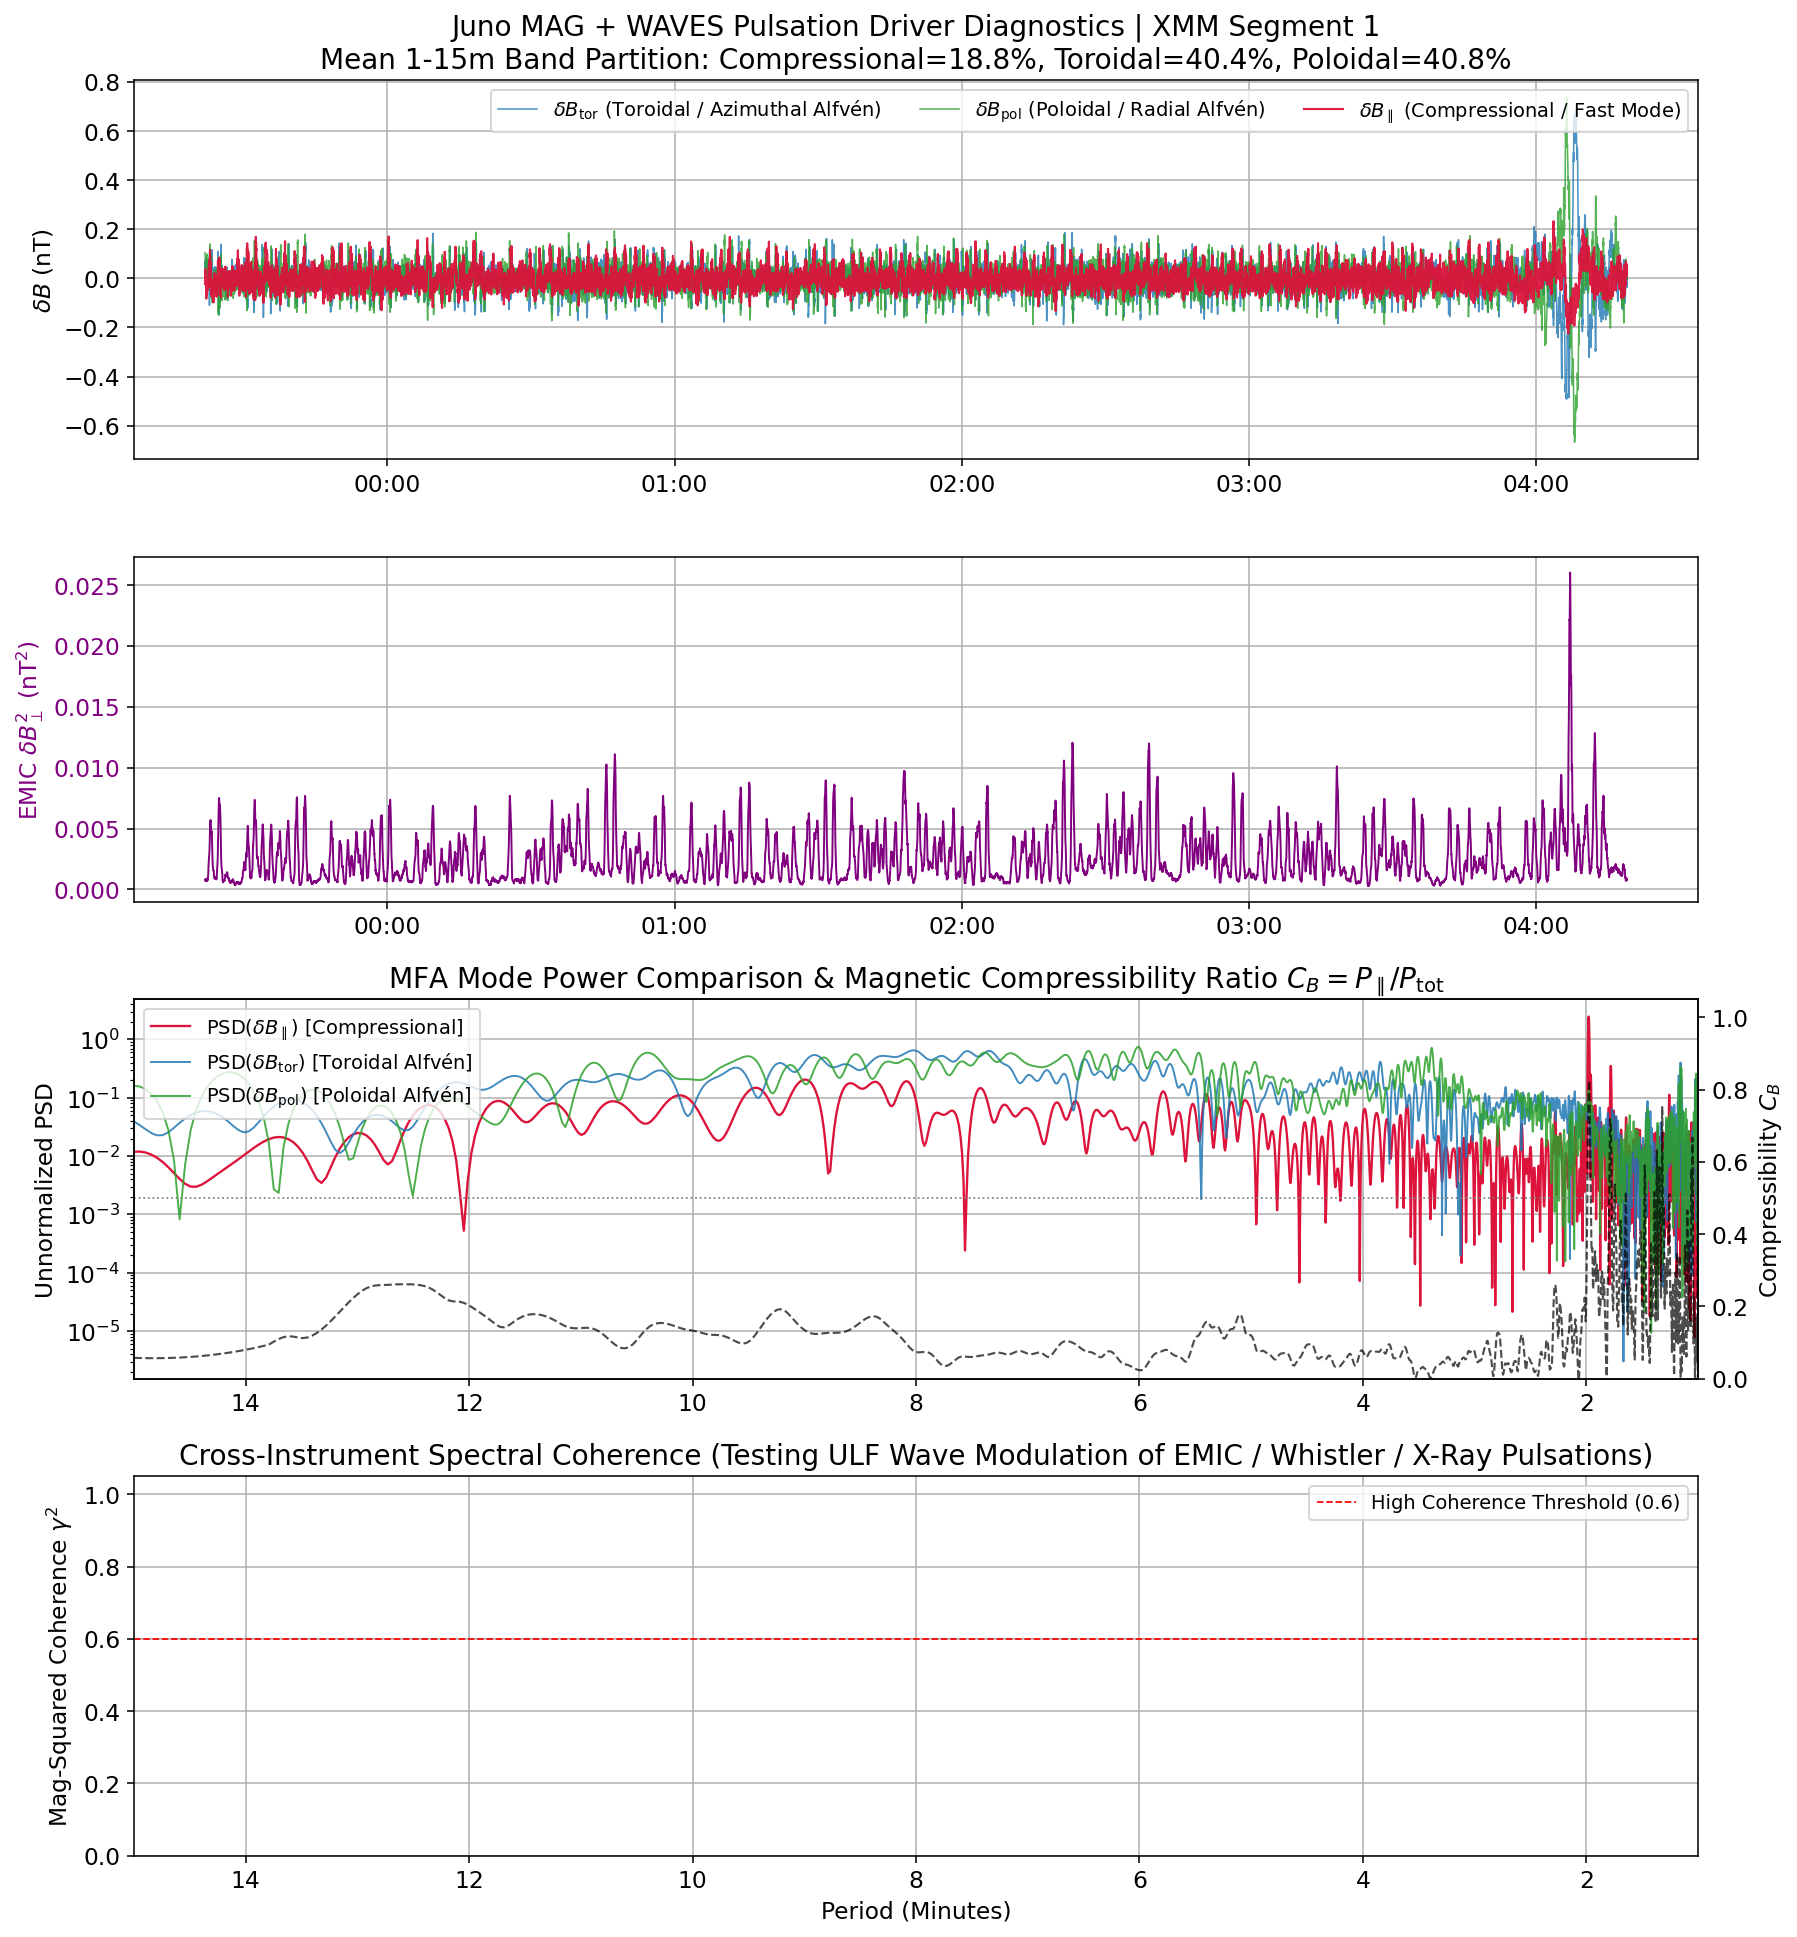

=== Physical Driver Summary for XMM Segment 1 ===
  • Dominant ULF Wave Mode (1-15m) : Poloidal Alfvén (Radial / Drift-Bounce)
  • Mean Compressibility (C_B)     : 0.19 (Toroidal=0.40, Poloidal=0.41)
  • Diagnostic Plot Saved          : FGM_FIGS/Driver_Diagnostics_P0801931901_Seg_1.png

[WAVES Fetch Warning] Could not load WAVES ESD: could not convert string to float: '2019-04-02'


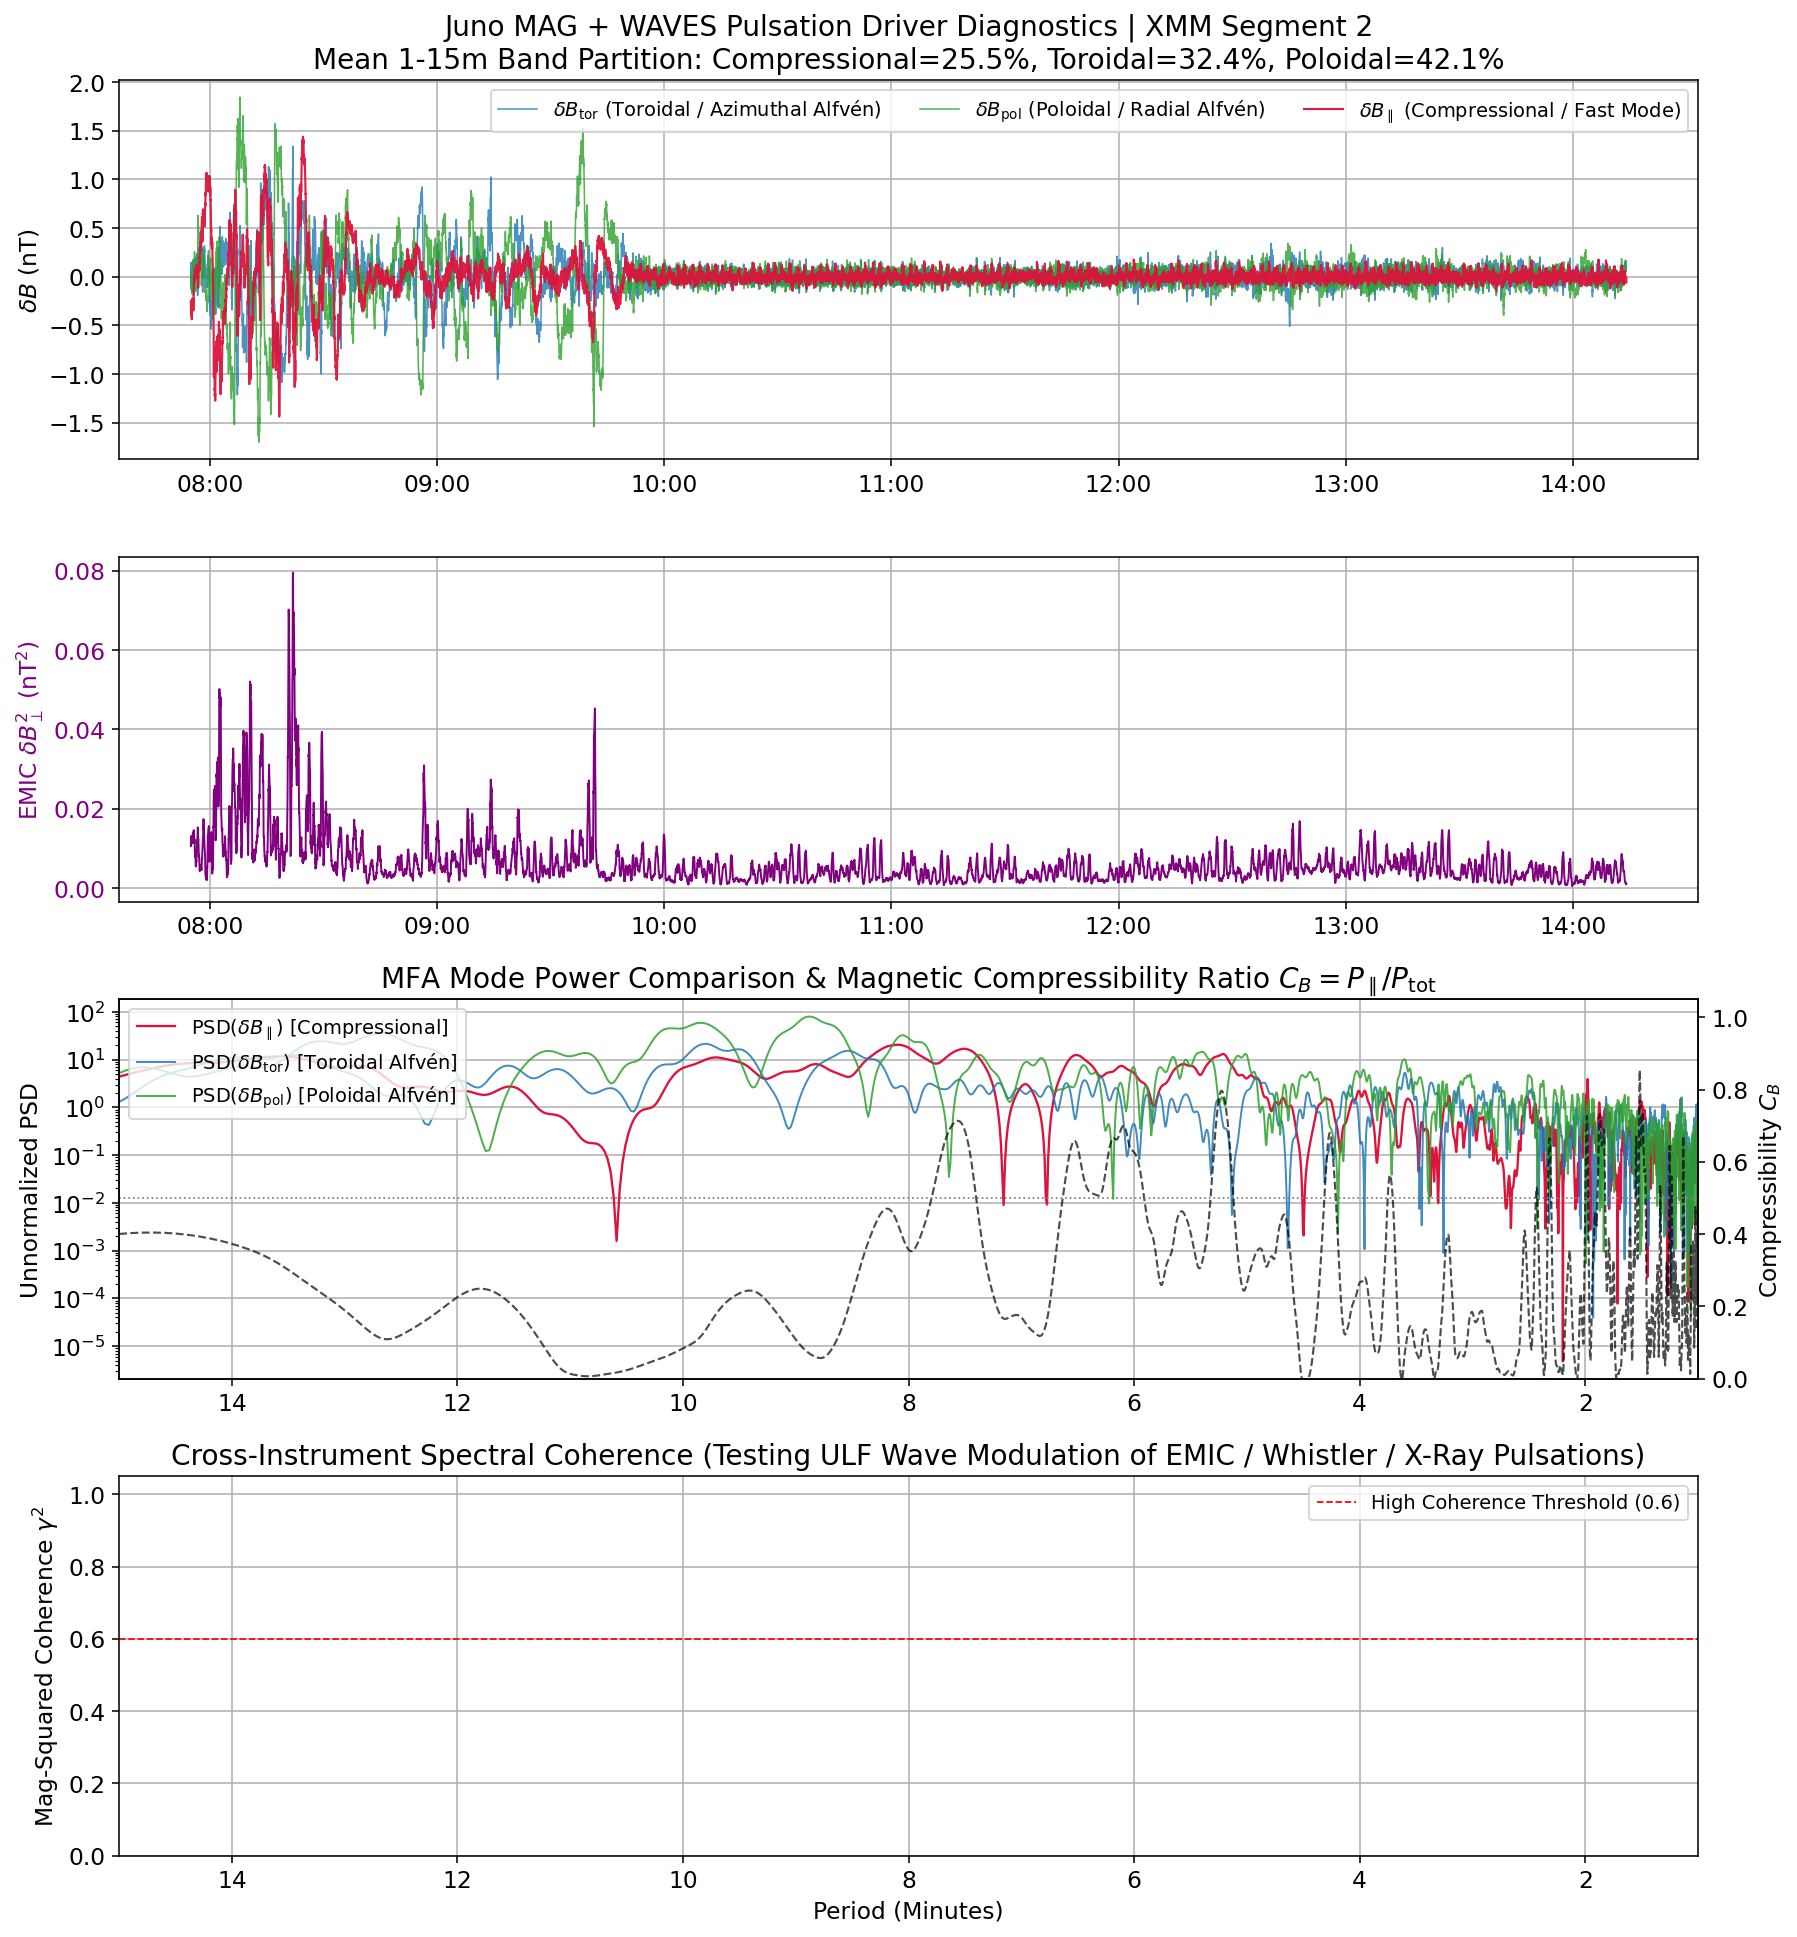

=== Physical Driver Summary for XMM Segment 2 ===
  • Dominant ULF Wave Mode (1-15m) : Poloidal Alfvén (Radial / Drift-Bounce)
  • Mean Compressibility (C_B)     : 0.25 (Toroidal=0.32, Poloidal=0.42)
  • Diagnostic Plot Saved          : FGM_FIGS/Driver_Diagnostics_P0801931901_Seg_2.png

[WAVES Fetch Warning] Could not load WAVES ESD: could not convert string to float: '2019-04-02'


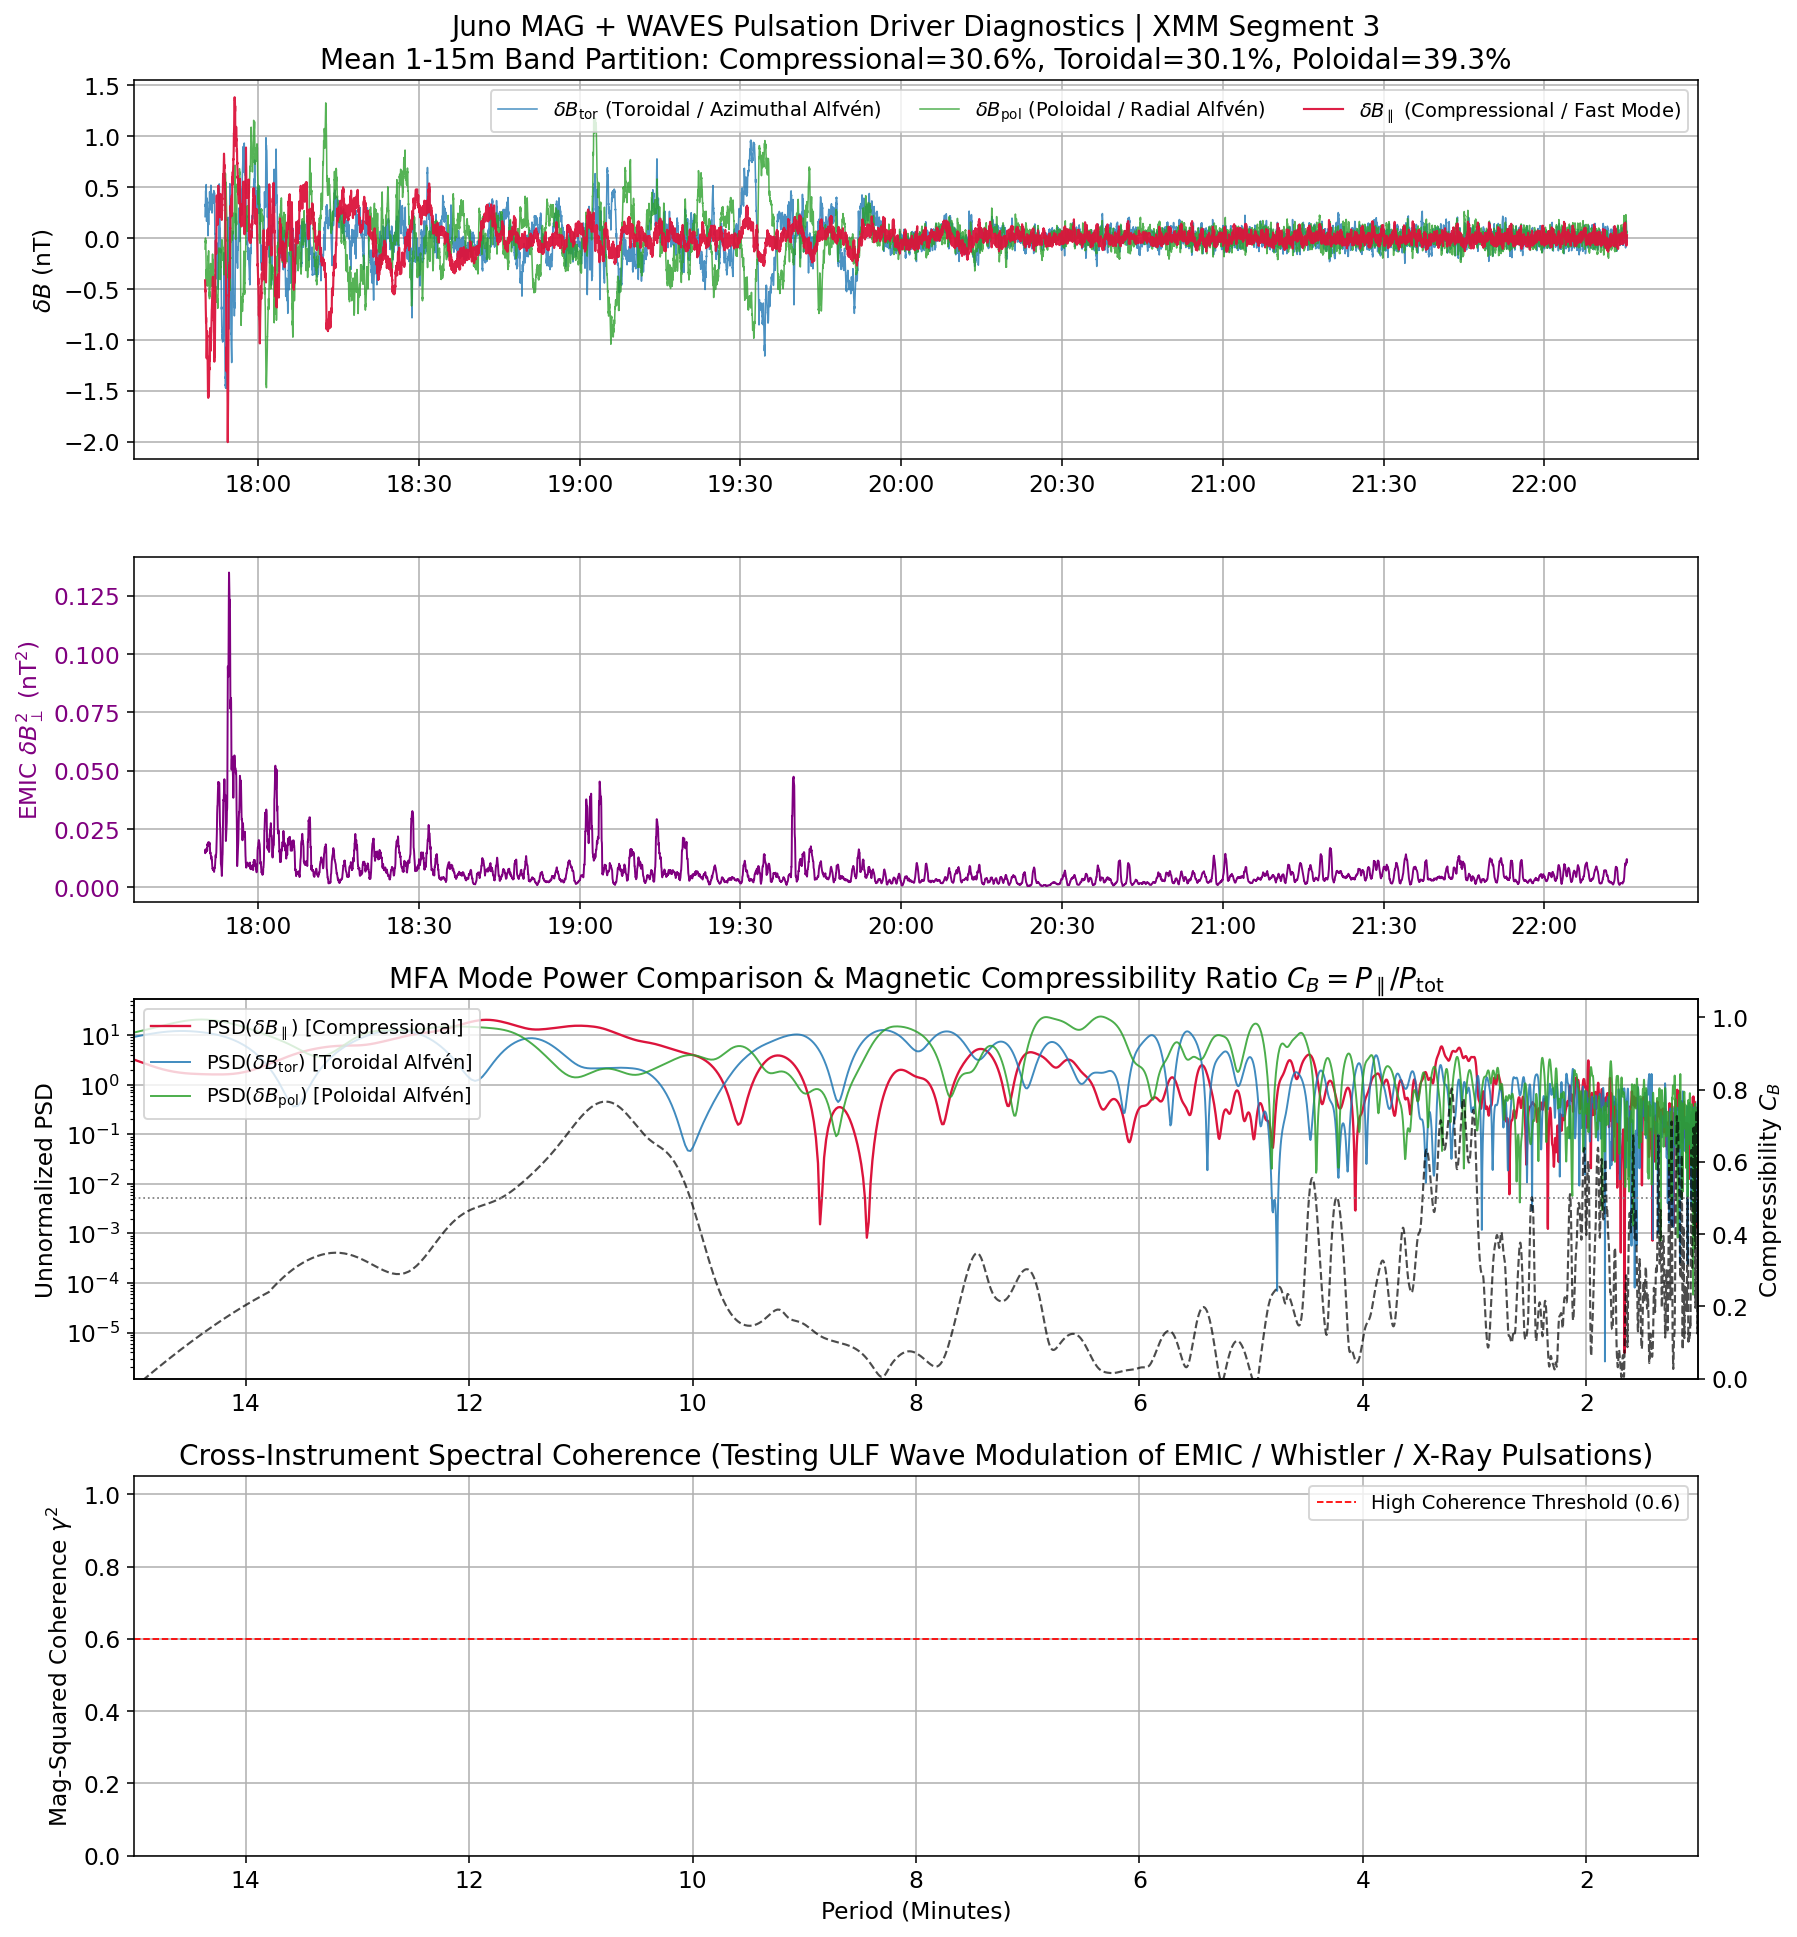

=== Physical Driver Summary for XMM Segment 3 ===
  • Dominant ULF Wave Mode (1-15m) : Poloidal Alfvén (Radial / Drift-Bounce)
  • Mean Compressibility (C_B)     : 0.31 (Toroidal=0.30, Poloidal=0.39)
  • Diagnostic Plot Saved          : FGM_FIGS/Driver_Diagnostics_P0801931901_Seg_3.png



In [44]:
# --- MULTI-INSTRUMENT DRIVER DIAGNOSTICS: MFA Decomposition, EMIC Envelope & WAVES/FGM Coherence ---
from astropy.time import Time
from astropy.timeseries import LombScargle
from das2 import get_source
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.signal as signal


def decompose_fgm_mfa(df_seg: pd.DataFrame, dt_med: float, cutoff_sec: float = MAX_PERIOD_SEC):
    """Rotates Planetocentric (Br, Btheta, Bphi) FGM data into Mean-Field-Aligned (MFA)

    coordinates:
      - dB_par : Compressional (parallel to background field B0)
      - dB_pol : Poloidal (meridional/radial perpendicular component)
      - dB_tor : Toroidal (azimuthal perpendicular component)
    Also extracts the high-frequency EMIC wave power envelope (0.03 - 0.45 Hz)
    if cadence allows.
    """
    B_vec = df_seg[["B1", "B2", "B3"]].to_numpy(dtype=float)
    fs = 1.0 / dt_med

    # 1. Low-pass filter (< 1/cutoff_sec Hz) to define the local background magnetic field vector B0(t)
    sos_lp = signal.butter(4, 1.0 / cutoff_sec, btype="lowpass", fs=fs, output="sos")
    B0_vec = signal.sosfiltfilt(sos_lp, B_vec, axis=0)
    B0_mag = np.linalg.norm(B0_vec, axis=1, keepdims=True)
    b_hat = B0_vec / np.where(B0_mag == 0, 1.0, B0_mag)  # Unit vector along B0

    # 2. In Planetocentric spherical coordinates (r, theta, phi), the radial unit vector is simply [1, 0, 0]
    r_hat = np.zeros_like(b_hat)
    r_hat[:, 0] = 1.0

    # Toroidal unit vector: e_tor = (b_hat x r_hat) / |b_hat x r_hat| (azimuthal /east-west)
    e_tor = np.cross(b_hat, r_hat)
    e_tor_norm = np.linalg.norm(e_tor, axis=1, keepdims=True)
    # Fallback to e_theta [0, 1, 0] if B0 is purely radial
    mask_parallel = (e_tor_norm[:, 0] < 1e-3)
    if np.any(mask_parallel):
        alt_ref = np.zeros_like(b_hat)
        alt_ref[:, 1] = 1.0
        e_tor[mask_parallel] = np.cross(b_hat[mask_parallel], alt_ref[mask_parallel])
        e_tor_norm = np.linalg.norm(e_tor, axis=1, keepdims=True)
    e_tor = e_tor / np.where(e_tor_norm == 0, 1.0, e_tor_norm)

    # Poloidal unit vector: e_pol = e_tor x b_hat (meridional / radial perpendicular)
    e_pol = np.cross(e_tor, b_hat)

    # 3. High-pass filter the perturbation vector dB = B - B0 in the ULF band (> 1/cutoff_sec Hz)
    sos_hp = signal.butter(4, 1.0 / cutoff_sec, btype="highpass", fs=fs, output="sos")
    dB_vec = signal.sosfiltfilt(sos_hp, B_vec, axis=0)

    df_seg = df_seg.copy()
    df_seg["dB_par"] = np.einsum("ij,ij->i", dB_vec, b_hat)  # Compressional
    df_seg["dB_pol"] = np.einsum("ij,ij->i", dB_vec, e_pol)  # Poloidal (radial Alfvén)
    df_seg["dB_tor"] = np.einsum("ij,ij->i", dB_vec, e_tor)  # Toroidal (azimuthal Alfvén)

    # 4. Extract EMIC Wave Power Envelope (0.03 - 0.40 Hz) if FGM cadence is ~1s (fs >= 0.9 Hz)
    if fs >= 0.9:
        sos_emic = signal.butter(4, [0.03, min(0.42 * fs, 0.45)], btype="bandpass", fs=fs, output="sos")
        dB_perp1_emic = signal.sosfiltfilt(sos_emic, np.einsum("ij,ij->i", B_vec, e_pol))
        dB_perp2_emic = signal.sosfiltfilt(sos_emic, np.einsum("ij,ij->i", B_vec, e_tor))
        # Instantaneous transverse EMIC wave power (nT^2) smoothed over 30s
        emic_raw_pwr = dB_perp1_emic**2 + dB_perp2_emic**2
        win_pts = max(1, int(round(30.0 / dt_med)))
        df_seg["EMIC_pwr"] = pd.Series(emic_raw_pwr).rolling(win_pts, center=True, min_periods=1).mean().to_numpy()
    else:
        df_seg["EMIC_pwr"] = np.nan

    return df_seg


def fetch_waves_whistler_ts(start_iso: str, end_iso: str, whis_min: float = 300.0, whis_max: float = 3000.0):
    """Fetches Juno WAVES whistler-band (300-3000 Hz) summed ESD time series via Das2."""
    try:
        source = get_source(SERVER_URL_WAVES)
        ds = source.get({"time": (start_iso, end_iso)})
        if len(ds) < 1:
            return None
        whis = ds[0]
        f_arr = whis["frequency"]["center"].array
        freqs = f_arr[0, :] if getattr(f_arr, "ndim", 1) > 1 else f_arr
        t_arr = whis["Time"]["center"].array
        times = t_arr[:, 0] if getattr(t_arr, "ndim", 1) > 1 else t_arr
        spec = whis["spec_dens"]["center"].array.squeeze()
        if spec.shape[1] != freqs.size:
            spec = spec.T
        spec = np.where((spec > 0) & np.isfinite(spec), spec, np.nan)
        mask_band = (freqs >= whis_min) & (freqs <= whis_max)
        sum_esd = np.nansum(spec[:, mask_band], axis=1)
        return pd.DataFrame({
            "Time": pd.to_datetime(np.array(times, dtype="datetime64[ms]")),
            "WAVES_ESD": sum_esd,
        }).sort_values("Time").dropna()
    except Exception as e:
        print(f"[WAVES Fetch Warning] Could not load WAVES ESD: {e}")
        return None


def diagnose_pulsation_drivers(seg_dict: dict, df_fgm_seg: pd.DataFrame, whis_min: float = 300.0, whis_max: float = 3000.0):
    """Runs the 4-part physical driver diagnostic on an XMM + FGM + WAVES segment."""
    if df_fgm_seg is None or df_fgm_seg.empty:
        return

    seg_id = seg_dict["segment_id"]
    t_b = seg_dict["t_binned"]
    xmm_counts = seg_dict["counts_binned"]
    t_xmm_dt = pd.to_datetime(Time(t_b, format="cxcsec", scale="tt").utc.datetime)
    start_iso, end_iso = t_xmm_dt[0].strftime("%Y-%m-%d %H:%M:%S"), t_xmm_dt[-1].strftime("%Y-%m-%d %H:%M:%S")

    # 1. MFA Coordinate Decomposition
    times_fgm = df_fgm_seg["Time"].to_numpy(dtype="datetime64[ms]")
    t_sec_fgm = (times_fgm - times_fgm[0]) / np.timedelta64(1, "s")
    dt_med = float(np.nanmedian(np.diff(t_sec_fgm)))

    df_mfa = decompose_fgm_mfa(df_fgm_seg, dt_med, cutoff_sec=MAX_PERIOD_SEC)

    # 2. Compute Compressibility & Alfvénic Power Ratios in the 1 - 15 min QPP Band
    fmin, fmax = 1.0 / MAX_PERIOD_SEC, 1.0 / MIN_PERIOD_SEC
    freqs_ls = np.linspace(fmin, fmax, 4000)
    periods_min = (1.0 / freqs_ls) / 60.0

    # Unnormalized PSD via Lomb-Scargle to compare physical variance (nT^2) between components
    psd_par = LombScargle(t_sec_fgm, df_mfa["dB_par"], normalization="psd").power(freqs_ls)
    psd_pol = LombScargle(t_sec_fgm, df_mfa["dB_pol"], normalization="psd").power(freqs_ls)
    psd_tor = LombScargle(t_sec_fgm, df_mfa["dB_tor"], normalization="psd").power(freqs_ls)
    psd_tot = psd_par + psd_pol + psd_tor

    comp_ratio_band = float(np.nanmean(psd_par / np.where(psd_tot == 0, 1.0, psd_tot)))
    tor_ratio_band = float(np.nanmean(psd_tor / np.where(psd_tot == 0, 1.0, psd_tot)))
    pol_ratio_band = float(np.nanmean(psd_pol / np.where(psd_tot == 0, 1.0, psd_tot)))

    # 3. Fetch WAVES Whistler ESD & Resample FGM + WAVES + XMM onto a common 10s grid for Coherence
    df_waves = fetch_waves_whistler_ts(start_iso, end_iso, whis_min=whis_min, whis_max=whis_max)

    grid_dt = 10.0  # 10-second common cadence
    t_grid = pd.date_range(start=df_mfa["Time"].iloc[0], end=df_mfa["Time"].iloc[-1], freq=f"{int(grid_dt)}s")
    df_grid = pd.DataFrame({"Time": t_grid}).set_index("Time")

    df_mfa_idx = df_mfa.set_index("Time")
    df_grid["dB_par"] = df_mfa_idx["dB_par"].resample(f"{int(grid_dt)}s").mean().interpolate(limit=6)
    df_grid["dB_perp"] = np.sqrt(df_mfa_idx["dB_pol"]**2 + df_mfa_idx["dB_tor"]**2).resample(f"{int(grid_dt)}s").mean().interpolate(limit=6)
    df_grid["EMIC_pwr"] = df_mfa_idx["EMIC_pwr"].resample(f"{int(grid_dt)}s").mean().interpolate(limit=6)

    if df_waves is not None and not df_waves.empty:
        # Log10 of WAVES ESD handles dynamic range spikes when testing linear wave modulation
        df_waves["log_ESD"] = np.log10(np.maximum(df_waves["WAVES_ESD"], 1e-18))
        df_grid["WAVES_logESD"] = df_waves.set_index("Time")["log_ESD"].resample(f"{int(grid_dt)}s").mean().interpolate(limit=6)
    else:
        df_grid["WAVES_logESD"] = np.nan

    df_xmm_ts = pd.DataFrame({"Time": t_xmm_dt, "XMM_counts": xmm_counts}).set_index("Time")
    df_grid["XMM_counts"] = df_xmm_ts["XMM_counts"].resample(f"{int(grid_dt)}s").mean().interpolate(limit=6)
    df_grid = df_grid.dropna(subset=["dB_par"])

    # 4. Plotting the 4-Panel Driver Diagnostic Figure
    fig, axes = plt.subplots(4, 1, figsize=(13, 14), dpi=140, gridspec_kw={"height_ratios": [1.1, 1.0, 1.1, 1.1]})
    ax_mfa, ax_env, ax_psd, ax_coh = axes

    # Panel 1: MFA Magnetic Field Perturbations (Compressional vs Poloidal vs Toroidal)
    ax_mfa.plot(df_mfa["Time"], df_mfa["dB_tor"], color="tab:blue", lw=0.8, alpha=0.8, label=r"$\delta B_{\mathrm{tor}}$ (Toroidal / Azimuthal Alfvén)")
    ax_mfa.plot(df_mfa["Time"], df_mfa["dB_pol"], color="tab:green", lw=0.8, alpha=0.8, label=r"$\delta B_{\mathrm{pol}}$ (Poloidal / Radial Alfvén)")
    ax_mfa.plot(df_mfa["Time"], df_mfa["dB_par"], color="crimson", lw=1.1, alpha=0.95, label=r"$\delta B_{\parallel}$ (Compressional / Fast Mode)")
    ax_mfa.set_ylabel(r"$\delta B$ (nT)")
    ax_mfa.set_title(
        f"Juno MAG + WAVES Pulsation Driver Diagnostics | XMM Segment {seg_id}\n"
        f"Mean 1-15m Band Partition: Compressional={comp_ratio_band*100:.1f}%, "
        f"Toroidal={tor_ratio_band*100:.1f}%, Poloidal={pol_ratio_band*100:.1f}%"
    )
    ax_mfa.legend(loc="upper right", ncols=3, fontsize="small")
    ax_mfa.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))

    # Panel 2: Wave-Particle Growth Proxies (FGM EMIC Power Envelope & WAVES Whistler ESD)
    ax_env.plot(df_mfa["Time"], df_mfa["EMIC_pwr"], color="purple", lw=1.0, label="FGM EMIC Band Power (0.03–0.45 Hz)")
    ax_env.set_ylabel(r"EMIC $\delta B_\perp^2$ ($\mathrm{nT}^2$)", color="purple")
    ax_env.tick_params(axis="y", labelcolor="purple")
    ax_env.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))

    if df_grid["WAVES_logESD"].notna().sum() > 20:
        ax_wav = ax_env.twinx()
        ax_wav.plot(df_grid.index, df_grid["WAVES_logESD"], color="darkorange", lw=1.0, alpha=0.85, label=f"WAVES log10 ESD ({whis_min:.0f}-{whis_max:.0f} Hz)")
        ax_wav.set_ylabel("WAVES log10(ESD)", color="darkorange")
        ax_wav.tick_params(axis="y", labelcolor="darkorange")
        ax_wav.grid(False)

    # Panel 3: MFA Component Power Spectral Density & Compressibility Ratio C_B(f)
    ax_psd.plot(periods_min, psd_par, color="crimson", lw=1.2, label=r"PSD($\delta B_\parallel$) [Compressional]")
    ax_psd.plot(periods_min, psd_tor, color="tab:blue", lw=1.0, alpha=0.85, label=r"PSD($\delta B_{\mathrm{tor}}$) [Toroidal Alfvén]")
    ax_psd.plot(periods_min, psd_pol, color="tab:green", lw=1.0, alpha=0.85, label=r"PSD($\delta B_{\mathrm{pol}}$) [Poloidal Alfvén]")
    ax_psd.set_yscale("log")
    ax_psd.set_xlim(MAX_PERIOD_SEC / 60.0, MIN_PERIOD_SEC / 60.0)
    ax_psd.set_ylabel("Unnormalized PSD")
    ax_psd.set_title("MFA Mode Power Comparison & Magnetic Compressibility Ratio $C_B = P_\parallel / P_{\mathrm{tot}}$")
    ax_psd.legend(loc="upper left", fontsize="small")

    ax_cb = ax_psd.twinx()
    comp_curve = signal.savgol_filter(psd_par / np.where(psd_tot == 0, 1.0, psd_tot), 51, 2)
    ax_cb.plot(periods_min, comp_curve, color="k", ls="--", lw=1.1, alpha=0.7, label="$C_B(T)$")
    ax_cb.axhline(0.5, color="gray", ls=":", lw=0.9)
    ax_cb.set_ylim(0, 1.05)
    ax_cb.set_ylabel("Compressibility $C_B$", color="k")
    ax_cb.grid(False)

    # Panel 4: Magnitude-Squared Coherence in the 1-15 min Band (FGM dB_par vs WAVES ESD & EMIC Power)
    nperseg = min(len(df_grid) // 2, int(round(1800.0 / grid_dt)))  # 30-min Welch window
    if nperseg >= 32:
        if df_grid["EMIC_pwr"].notna().sum() > nperseg:
            f_c, coh_emic = signal.coherence(
                signal.detrend(df_grid["dB_par"].fillna(0)),
                signal.detrend(df_grid["EMIC_pwr"].fillna(0)),
                fs=1.0 / grid_dt,
                nperseg=nperseg,
                noverlap=int(nperseg * 0.75),
            )
            valid = f_c > 0
            ax_coh.plot((1.0 / f_c[valid]) / 60.0, coh_emic[valid], color="purple", lw=1.3, label=r"Coherence: $\delta B_\parallel$ vs. FGM EMIC Power")

        if df_grid["WAVES_logESD"].notna().sum() > nperseg:
            f_w, coh_wav = signal.coherence(
                signal.detrend(df_grid["dB_par"].fillna(0)),
                signal.detrend(df_grid["WAVES_logESD"].fillna(0)),
                fs=1.0 / grid_dt,
                nperseg=nperseg,
                noverlap=int(nperseg * 0.75),
            )
            valid_w = f_w > 0
            ax_coh.plot((1.0 / f_w[valid_w]) / 60.0, coh_wav[valid_w], color="darkorange", lw=1.3, label=r"Coherence: $\delta B_\parallel$ vs. WAVES Whistler ESD")

        if df_grid["XMM_counts"].notna().sum() > nperseg:
            f_x, coh_xmm = signal.coherence(
                signal.detrend(df_grid["dB_par"].fillna(0)),
                signal.detrend(df_grid["XMM_counts"].fillna(0)),
                fs=1.0 / grid_dt,
                nperseg=nperseg,
                noverlap=int(nperseg * 0.75),
            )
            valid_x = f_x > 0
            ax_coh.plot((1.0 / f_x[valid_x]) / 60.0, coh_xmm[valid_x], color="teal", ls="-.", lw=1.2, label=r"Coherence: $\delta B_\parallel$ vs. XMM X-Ray Counts")

    ax_coh.axhline(0.6, color="red", ls="--", lw=0.9, label="High Coherence Threshold (0.6)")
    ax_coh.set_xlim(MAX_PERIOD_SEC / 60.0, MIN_PERIOD_SEC / 60.0)
    ax_coh.set_ylim(0, 1.05)
    ax_coh.set_xlabel("Period (Minutes)")
    ax_coh.set_ylabel("Mag-Squared Coherence $\gamma^2$")
    ax_coh.set_title("Cross-Instrument Spectral Coherence (Testing ULF Wave Modulation of EMIC / Whistler / X-Ray Pulsations)")
    ax_coh.legend(loc="upper right", ncols=2, fontsize="small")

    plt.tight_layout()
    out_diag = os.path.join(FGM_FIG_OUTDIR, f"Driver_Diagnostics_{XMM_OBS_ID}_Seg_{seg_id}.png")
    plt.savefig(out_diag, dpi=150)
    plt.show()

    # Summary Diagnosis Printout
    dominant_mode = "Compressional (Fast Magnetosonic)" if comp_ratio_band > 0.5 else (
        "Toroidal Alfvén (Azimuthal FLR)" if tor_ratio_band > pol_ratio_band else "Poloidal Alfvén (Radial / Drift-Bounce)"
    )
    print(f"=== Physical Driver Summary for XMM Segment {seg_id} ===")
    print(f"  • Dominant ULF Wave Mode (1-15m) : {dominant_mode}")
    print(f"  • Mean Compressibility (C_B)     : {comp_ratio_band:.2f} (Toroidal={tor_ratio_band:.2f}, Poloidal={pol_ratio_band:.2f})")
    print(f"  • Diagnostic Plot Saved          : {out_diag}\n")


# --- Execute Multi-Instrument Driver Diagnostics Across All Segments ---
for seg in segments_xmm:
    s_id = seg["segment_id"]
    if s_id in fgm_results and fgm_results[s_id] is not None:
        diagnose_pulsation_drivers(seg, fgm_results[s_id], whis_min=300.0, whis_max=3000.0)